# 26SP-4

Use the earliest steady-front cluster run under `new_paper_calculations/26-03-31/` that contains saved profile data to check whether the kinetic term `h u^2` is negligible compared with the pressure `P`.

Definitions used in the notebook:

- Nuclear side: `R_N = h_N u_N^2 / P_N`
- Quark side: `R_Q(x) = |Pi - P_Q(x)| / P_Q(x)`

The absolute value on the quark side is used only to remove tiny roundoff-level sign flips when `Pi - P_Q` is numerically extremely small.


In [1]:
# LOAD_BVP_6APR_RUN_AND_COMPUTE_HU2_OVER_P
import json
from pathlib import Path

import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import IntegrationWarning
from matplotlib.lines import Line2D

import RMFsolver.constants as const
from RMFsolver.phase_velocity import PNM_n, edensNM_n, PQM

TitleFont = 18
LabelFont = 16
TickFont = 16
LegendFont = 14
AnnotFont = 14


def add_nonoverlap_labels(ax, entries, radius_pts=10.0, min_sep_pts=16.0, max_radius_pts=34.0):
    fig = ax.figure
    fig.canvas.draw()
    if not entries:
        return

    pts_px = np.array([ax.transData.transform((entry['x'], entry['y'])) for entry in entries], dtype=float)
    angles = np.linspace(0.0, 2.0 * np.pi, len(entries), endpoint=False)
    radius_px = radius_pts * fig.dpi / 72.0
    min_sep_px = min_sep_pts * fig.dpi / 72.0
    max_radius_px = max_radius_pts * fig.dpi / 72.0
    pos_px = pts_px + np.column_stack([radius_px * np.cos(angles), radius_px * np.sin(angles)])

    for _ in range(500):
        moved = False
        for i in range(len(entries)):
            for j in range(i + 1, len(entries)):
                delta = pos_px[i] - pos_px[j]
                dist = np.hypot(delta[0], delta[1])
                if dist < min_sep_px:
                    if dist < 1.0e-9:
                        delta = np.array([1.0, 0.0])
                        dist = 1.0
                    shift = 0.5 * (min_sep_px - dist) * delta / dist
                    pos_px[i] += shift
                    pos_px[j] -= shift
                    moved = True

            delta0 = pos_px[i] - pts_px[i]
            dist0 = np.hypot(delta0[0], delta0[1])
            if dist0 < radius_px:
                if dist0 < 1.0e-9:
                    delta0 = np.array([1.0, 0.0])
                    dist0 = 1.0
                pos_px[i] += (radius_px - dist0) * delta0 / dist0
                moved = True
            elif dist0 > max_radius_px:
                pos_px[i] -= 0.18 * (dist0 - max_radius_px) * delta0 / dist0
                moved = True
        if not moved:
            break

    for entry, xy_px, label_px in zip(entries, pts_px, pos_px):
        offset_pts = (label_px - xy_px) * 72.0 / fig.dpi
        ax.annotate(
            entry['label'],
            xy=(entry['x'], entry['y']),
            xytext=tuple(offset_pts),
            textcoords='offset points',
            ha='center',
            va='center',
            fontsize=AnnotFont,
            color=entry['color'],
            bbox=dict(boxstyle='round,pad=0.14', facecolor='white', edgecolor='none', alpha=0.92),
            arrowprops=dict(arrowstyle='-', lw=0.6, color=entry['color'], alpha=0.55),
            zorder=5,
        )


results_root = Path('/Users/janshao/NSM_related/new_paper_calculations/26-04-06')
run_dir = results_root / 'steady_front_bvp_run_20260407_151939'
if not run_dir.is_dir():
    raise RuntimeError(f'Requested run folder not found: {run_dir}')

config = json.loads((run_dir / 'run_config.json').read_text())
rows_all = [json.loads(line) for line in (run_dir / 'trial_summary.jsonl').read_text().splitlines() if line.strip()]
rows = []
needed_profile_keys = {'x', 'muB', 'muK', 'Pi', 'u_N'}

for row in rows_all:
    point_index = int(row['point_index'])
    raw_npz = str(row.get('npz_path', ''))
    candidates = []
    if raw_npz:
        candidates.append(run_dir / Path(raw_npz).name)
    candidates.extend(sorted(run_dir.glob(f'point_{point_index:03d}__*.npz')))

    npz_path = None
    for candidate in candidates:
        if not candidate.exists():
            continue
        try:
            with np.load(candidate) as data:
                if needed_profile_keys.issubset(set(data.files)):
                    npz_path = candidate
                    break
        except Exception:
            continue
    if npz_path is None:
        continue

    row = dict(row)
    row['npz_path_local'] = str(npz_path)
    row['plot_id'] = point_index
    rows.append(row)

if not rows:
    raise RuntimeError(f'No profile-bearing .npz files found in {run_dir.name}')

n0 = 0.16 * const.MeV_fm**3
T_run = float(config['T'])
B14_run = float(config['B_one_forth'])
ms_run = float(config.get('ms', 0.0))
nB_N = float(config['nB_factor']) * n0

P_N = float(PNM_n(nB_N, T_run))
e_N = float(edensNM_n(nB_N, T_run))
h_N = float(P_N + e_N)

for row in rows:
    npz_path = Path(row['npz_path_local'])
    with np.load(npz_path) as data:
        Pi_val = float(data['Pi'])
        u_N_val = float(data['u_N'])
        x_nm = np.asarray(data['x'], dtype=float) * const.MeV_fm / 1.0e9
        muB_profile = np.asarray(data['muB'], dtype=float)
        muK_profile = np.asarray(data['muK'], dtype=float)
        P_Q = np.array([
            PQM(float(muB), float(muK), B14_run, T_run, ms=ms_run)
            for muB, muK in zip(muB_profile, muK_profile)
        ])
        hu2_Q = Pi_val - P_Q
        ratio_Q_mag = np.abs(hu2_Q / P_Q)

        # Use the branch selected by the latest BVP solver, rather than
        # re-classifying from a plotting threshold on the saved muK profile.
        branch_from_result = str(row.get('branch_label', '')).strip()
        row['branch'] = branch_from_result if branch_from_result == 'muK-rich' else 'muK-rich'
        row['muK_profile_max_abs'] = float(np.max(np.abs(muK_profile)))
        row['Pi'] = Pi_val
        row['u_N'] = u_N_val
        row['jB_scaled'] = float(row['jB'] / n0 * const.m_per_sec)
        row['ratio_N'] = float(h_N * u_N_val * u_N_val / P_N)
        row['ratio_Q_max'] = float(np.max(ratio_Q_mag))
        row['ratio_Q_min'] = float(np.min(ratio_Q_mag))
        row['ratio_Q_end'] = float(ratio_Q_mag[-1])
        row['x_nm'] = x_nm
        row['ratio_Q_profile'] = ratio_Q_mag

rows_sorted = sorted(rows, key=lambda r: float(r['aQstar']))
rich_rows = [r for r in rows_sorted if r['branch'] == 'muK-rich']
poor_rows = []

# Select representative profiles across the available profile-bearing branch.
if len(rows_sorted) <= 4:
    selected_rows = rows_sorted
else:
    idx = np.unique(np.round(np.linspace(0, len(rows_sorted) - 1, 4)).astype(int))
    selected_rows = [rows_sorted[i] for i in idx]
selected_ids = [row['plot_id'] for row in selected_rows]
row_by_id = {row['plot_id']: row for row in rows_sorted}

print(f'Using BVP run: {run_dir.name}')
print(f"T = {T_run:g} MeV, nB_N = {config['nB_factor']} n0, B^(1/4) = {B14_run:g} MeV")
print(f"tail_eps = {config.get('tail_eps')}, n_mesh = {config.get('n_mesh')}")
print(f'Profile-bearing points: {[row["plot_id"] for row in rows_sorted]}')
print(f'P_N = {P_N:.6e}, h_N = {h_N:.6e}')
print('')
print('Point summary for h u^2 / P:')
for row in rows_sorted:
    print(
        f"  point {row['plot_id']:2d}: {row['branch']}, aQ={row['aQstar']:.6g}, "
        f"jB/n0={row['jB_scaled']:.3f} m/s, "
        f"R_N={row['ratio_N']:.3e}, R_Q[min,max]=[{row['ratio_Q_min']:.3e}, {row['ratio_Q_max']:.3e}]"
    )

print('')
print('Representative points:', selected_ids)


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using BVP run: steady_front_bvp_run_20260407_151939
T = 10 MeV, nB_N = 2.0 n0, B^(1/4) = 180 MeV
tail_eps = 1e-06, n_mesh = 300
Profile-bearing points: [1, 2, 3, 4, 5, 6, 7, 8]
P_N = 1.716835e+08, h_N = 2.589809e+09

Point summary for h u^2 / P:
  point  1: muK-rich, aQ=0.05, jB/n0=11.527 m/s, R_N=5.575e-15, R_Q[min,max]=[5.208e-16, 2.968e-14]
  point  2: muK-rich, aQ=0.116667, jB/n0=28.905 m/s, R_N=3.506e-14, R_Q[min,max]=[1.024e-14, 2.941e-12]
  point  3: muK-rich, aQ=0.183333, jB/n0=50.135 m/s, R_N=1.055e-13, R_Q[min,max]=[5.208e-16, 2.792e-12]
  point  4: muK-rich, aQ=0.25, jB/n0=76.972 m/s, R_N=2.486e-13, R_Q[min,max]=[3.298e-15, 2.193e-12]
  point  5: muK-rich, aQ=0.316667, jB/n0=111.232 m/s, R_N=5.192e-13, R_Q[min,max]=[4.513e-15, 2.146e-12]
  point  6: muK-rich, aQ=0.383333, jB/n0=154.905 m/s, R_N=1.007e-12, R_Q[min,max]=[3.298e-15, 2.313e-12]
  point  7: muK-rich, aQ=0.45, jB/n0=210.421 m/s, R_N=1.858e-12, R_Q[min,max]=[3.020e-14, 2.871e-12]
  point  8: muK-rich, aQ=0.516667, 

Saved figure to /Users/janshao/NSM_related/new_paper_calculations/26-04-06/steady_front_bvp_run_20260407_151939_hu2_over_p_summary_26SP4.pdf


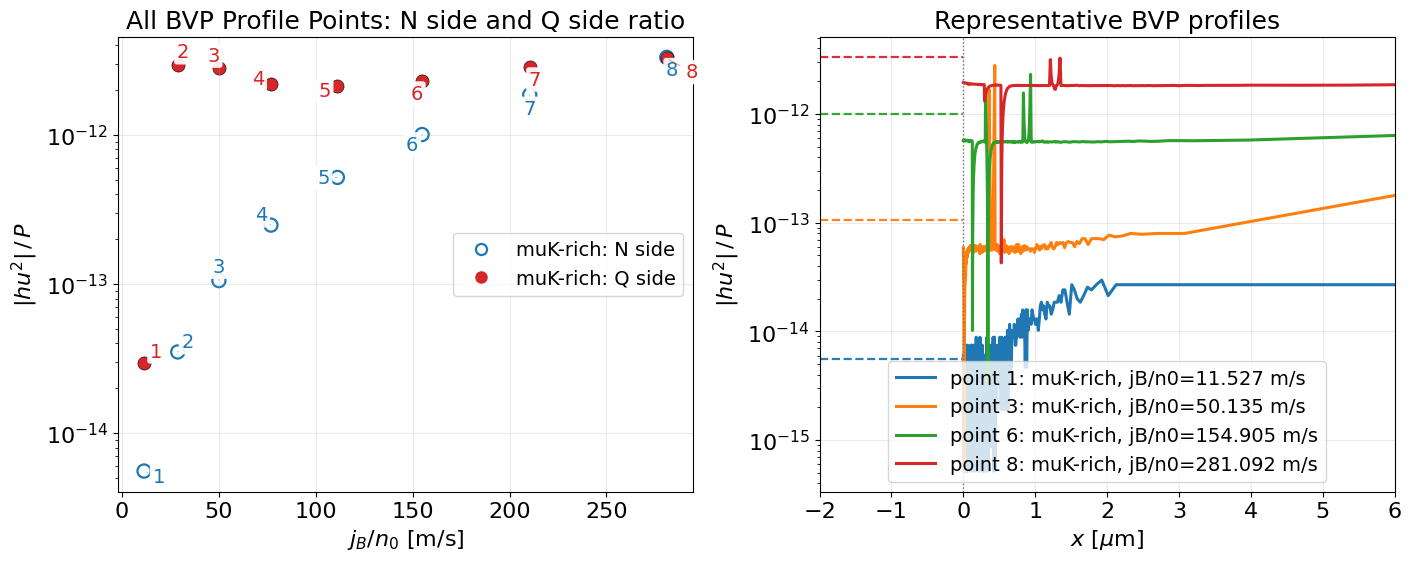

In [2]:
# VISUALIZE_HU2_OVER_P_BVP_6APR

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
palette = plt.get_cmap('tab10').colors
color_by_tid = {tid: palette[i % len(palette)] for i, tid in enumerate(selected_ids)}

branch_rows = rows_sorted
xvals = [r['jB_scaled'] for r in branch_rows]
yN = [r['ratio_N'] for r in branch_rows]
yQ = [r['ratio_Q_max'] for r in branch_rows]
axes[0].scatter(xvals, yN, marker='o', s=90, facecolors='none', edgecolors='C0', linewidths=1.6, label='muK-rich: N side')
axes[0].scatter(xvals, yQ, marker='o', s=90, c='C3', edgecolors='k', linewidths=0.4, label='muK-rich: Q side')

label_entries = []
for row in rows_sorted:
    label_entries.append({'x': row['jB_scaled'], 'y': row['ratio_N'], 'label': str(row['plot_id']), 'color': 'C0'})
    label_entries.append({'x': row['jB_scaled'], 'y': row['ratio_Q_max'], 'label': str(row['plot_id']), 'color': 'C3'})
add_nonoverlap_labels(axes[0], label_entries, radius_pts=10.0, min_sep_pts=15.0, max_radius_pts=28.0)

x_left_nm = np.linspace(-2.0, 0.0, 100)
for tid in selected_ids:
    row = row_by_id[tid]
    color = color_by_tid[tid]
    label = f"point {tid}: {row['branch']}, jB/n0={row['jB_scaled']:.3f} m/s"
    y_left = np.full_like(x_left_nm, row['ratio_N'])
    axes[1].plot(x_left_nm, y_left, ls='--', lw=1.6, color=color, alpha=0.95)
    axes[1].plot(row['x_nm'], row['ratio_Q_profile'], lw=2.2, color=color, label=label)

axes[0].set_yscale('log')
axes[0].set_xlabel(r'$j_B / n_0$ [m/s]', fontsize=LabelFont)
axes[0].set_ylabel(r'$|h u^2| \, / \, P$', fontsize=LabelFont)
axes[0].set_title(r'All BVP Profile Points: N side and Q side ratio', fontsize=TitleFont)
axes[0].grid(alpha=0.25)

legend_handles = [
    Line2D([0], [0], marker='o', color='C0', markerfacecolor='none', linestyle='None', markersize=8, markeredgewidth=1.6, label='muK-rich: N side'),
    Line2D([0], [0], marker='o', color='C3', linestyle='None', markersize=8, label='muK-rich: Q side'),
]
axes[0].legend(handles=legend_handles, fontsize=LegendFont, loc='center right')

axes[1].axvline(0.0, color='0.45', lw=1.0, ls=':')
axes[1].set_yscale('log')
axes[1].set_xlabel(r'$x$ [$\mu$m]', fontsize=LabelFont)
axes[1].set_ylabel(r'$|h u^2| \, / \, P$', fontsize=LabelFont)
axes[1].set_title(r'Representative BVP profiles', fontsize=TitleFont)
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=LegendFont, loc='lower center')
axes[1].set_xlim(-2, 6)

for ax in axes:
    ax.tick_params(axis='both', labelsize=TickFont)

output_pdf = results_root / f'{run_dir.name}_hu2_over_p_summary_26SP4.pdf'
fig.savefig(output_pdf, format='pdf', bbox_inches='tight')
print(f'Saved figure to {output_pdf}')
plt.show()


## Test 1D $a_{Q^*}$ Shooting and visualize

/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shoot1d jB=0.5, aQstar=0.3, tail_norm=(-0.311084), tail_raw=(-2.98561e-08), ok=True
shoot1d jB=0.333333, aQstar=0.3, tail_norm=(0.0903072), tail_raw=(5.8145e-09), ok=True
shoot1d jB=0.333333, aQstar=0.3, tail_norm=(0.0903072), tail_raw=(5.8145e-09), ok=True
shoot1d jB=0.5, aQstar=0.3, tail_norm=(-0.311084), tail_raw=(-2.98561e-08), ok=True
shoot1d jB=0.365171, aQstar=0.3, tail_norm=(-0.0147537), tail_raw=(-9.69603e-10), ok=True
shoot1d jB=0.360523, aQstar=0.3, tail_norm=(0.000334569), tail_raw=(2.16457e-11), ok=True
shoot1d jB=0.360626, aQstar=0.3, tail_norm=(-2.99704e-06), tail_raw=(-1.93905e-13), ok=True
shoot1d jB=0.360624, aQstar=0.3, tail_norm=(2.94545e-06), tail_raw=(1.90566e-13), ok=True
shoot1d jB=0.360624, aQstar=0.5, tail_norm=(0.717568), tail_raw=(8.18402e-08), ok=True
shoot1d jB=0.240416, aQstar=0.5, tail_norm=(0.955553), tail_raw=(1.03518e-07), ok=True
shoot1d jB=0.540936, aQstar=0.5, tail_norm=(0.403301), tail_raw=(4.95359e-08), ok=True
shoot1d jB=0.160277, aQstar=0.5, ta

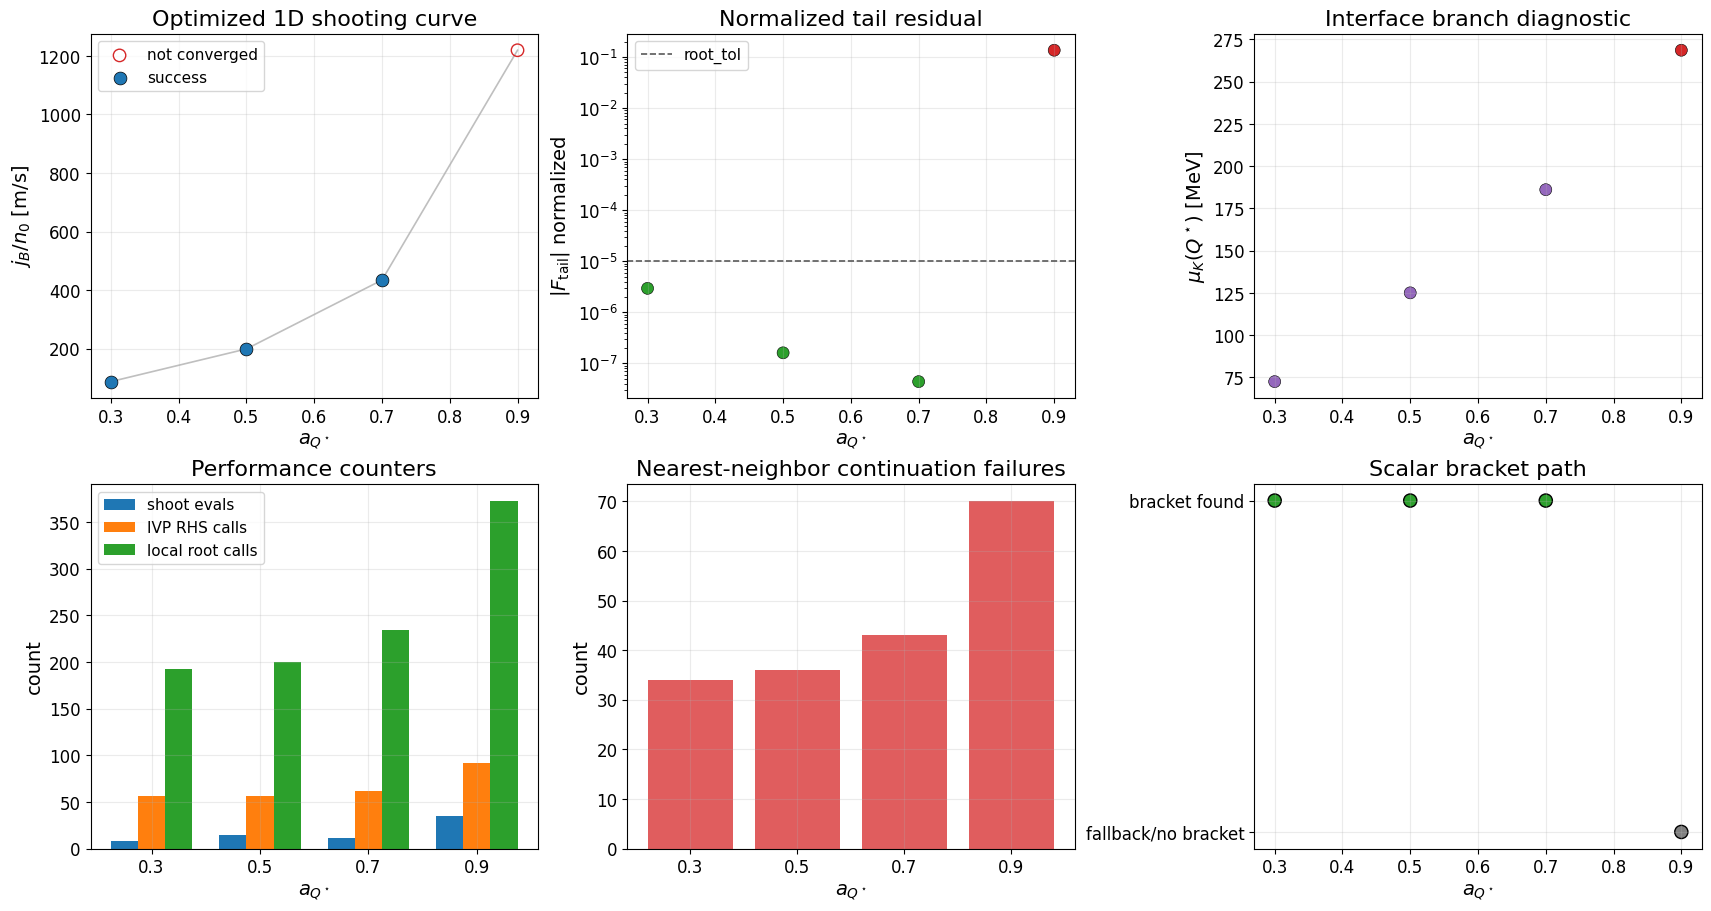

rerunning profile for aQstar=0.3, jB=0.360624, bounds=(0.3534112814290911, 0.367836231691503)
shoot1d jB=0.360624, aQstar=0.3, tail_norm=(2.94545e-06), tail_raw=(1.90566e-13), ok=True
rerunning profile for aQstar=0.9, jB=5, bounds=(4.8999999999999995, 5.0)
shoot1d jB=5, aQstar=0.9, tail_norm=(0.136337), tail_raw=(1.49686e-07), ok=True
shoot1d jB=4.9, aQstar=0.9, tail_norm=(0.138826), tail_raw=(1.49339e-07), ok=True
shoot1d jB=5, aQstar=0.9, tail_norm=(0.136337), tail_raw=(1.49686e-07), ok=True
shoot1d jB=5, aQstar=0.9, tail_norm=(0.136337), tail_raw=(1.49686e-07), ok=True
shoot1d jB=5, aQstar=0.9, tail_norm=(0.136337), tail_raw=(1.49686e-07), ok=True


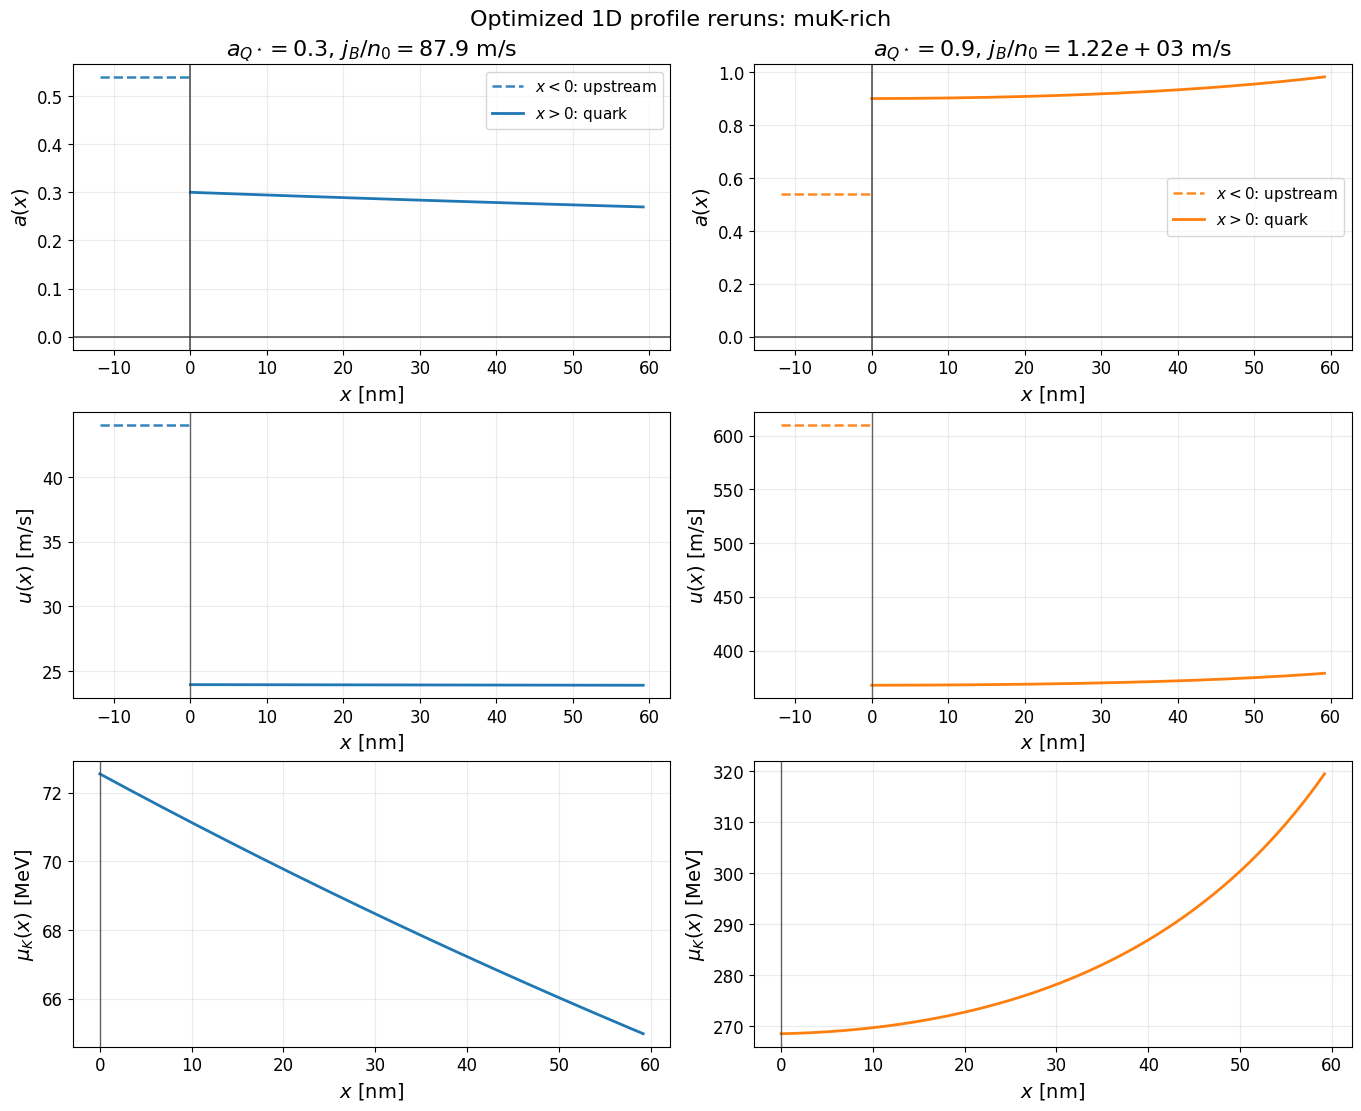

In [1]:
# TEST_OPTIMIZED_1D_AQSTAR_SHOOTING_AND_VISUALIZE
# Fast test for the optimized 1D steady-front solver.
# Default behavior is scalar-only: it does NOT reconstruct profiles for every point.

import time
import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.phase_velocity import extract_jB_curve_vs_aQstar, solve_steady_front_1d_aQstar

# -------------------------
# Editable test parameters
# -------------------------
T_test = 10.0
n0 = 0.16 * const.MeV_fm**3
nB_N_test = 2.0 * n0
B14_test = 180.0
ms_test = 0.0

# Keep this small for a quick smoke/performance test. Increase for production.
aQstar_values_test = np.array([0.30, 0.50, 0.7, 0.9], dtype=float)
jB_guess_test = 0.5
jB_bounds_test = (0.02, 5.0)

x_max_test = 3.0e5  # Profile domain; change this line to tune xmax.
n_eval_test = 180
root_tol_test = 1.0e-5
max_nfev_test = 12
return_profile_test = False  # Keep False for fast scalar curve extraction.
verb_test = True             # False, True, or "full".

# Optional profile reruns for selected aQstar values.
RUN_PROFILE_RERUN = True
profile_aQstar_targets = np.array([0.30, 0.90], dtype=float)
profile_n_eval_test = 180

# Font controls
TitleFont = 16
LabelFont = 14
TickFont = 12
LegendFont = 11

# -------------------------
# Run optimized scalar 1D scan
# -------------------------
t0 = time.perf_counter()
curve_1d = extract_jB_curve_vs_aQstar(
    T=T_test,
    nB_N=nB_N_test,
    B_one_forth=B14_test,
    aQstar_values=aQstar_values_test,
    ms=ms_test,
    x_max=x_max_test,
    n_eval=n_eval_test,
    root_tol=root_tol_test,
    max_nfev=max_nfev_test,
    jB_guess=jB_guess_test,
    jB_bounds=jB_bounds_test,
    return_profile=return_profile_test,
    verb=verb_test,
)
elapsed = time.perf_counter() - t0

results_1d = curve_1d['results']
branch_label_1d = curve_1d['branch_label']
print(f"optimized 1D aQstar scan branch: {branch_label_1d}")
print(f"success: {np.count_nonzero(curve_1d['success_flags'])}/{len(results_1d)}")
print(f"elapsed: {elapsed:.3f} s for {len(results_1d)} aQstar points")

for i, res in enumerate(results_1d):
    print(
        f"[{i}] aQstar={res.get('aQstar', np.nan):.6g}, "
        f"success={res.get('success')}, "
        f"jB={res.get('jB', np.nan):.6g}, "
        f"jB/n0={res.get('jB', np.nan) / n0 * const.m_per_sec:.6g} m/s, "
        f"tail_norm={res.get('tail_residual_norm', np.nan):.6g}, "
        f"tail_raw={res.get('tail_residual', np.nan):.6g}, "
        f"muK_Qstar={res.get('muK_Qstar', np.nan):.6g}, "
        f"root={res.get('_root_method', '')}, "
        f"bracket={res.get('_bracket_found', False)}, "
        f"shoot_evals={res.get('shooting_evals', 0)}, "
        f"rhs={res.get('ivp_rhs_calls', 0)}, "
        f"local_roots={res.get('local_root_calls', 0)}, "
        f"fast_fail={res.get('local_fast_failures', 0)}, "
        f"message={res.get('message', '')}"
    )

# -------------------------
# Plot scalar scan summary and speed diagnostics
# -------------------------
a_all = np.array([res.get('aQstar', np.nan) for res in results_1d], dtype=float)
jB_all = np.array([res.get('jB', np.nan) for res in results_1d], dtype=float)
tail_all = np.array([res.get('tail_residual', np.nan) for res in results_1d], dtype=float)
tail_norm_all = np.array([res.get('tail_residual_norm', np.nan) for res in results_1d], dtype=float)
muK_star_all = np.array([res.get('muK_Qstar', np.nan) for res in results_1d], dtype=float)
success_all = np.array([bool(res.get('success', False)) for res in results_1d], dtype=bool)
shoot_evals = np.array([res.get('shooting_evals', 0) for res in results_1d], dtype=float)
ivp_rhs = np.array([res.get('ivp_rhs_calls', 0) for res in results_1d], dtype=float)
local_roots = np.array([res.get('local_root_calls', 0) for res in results_1d], dtype=float)
fast_fail = np.array([res.get('local_fast_failures', 0) for res in results_1d], dtype=float)
bracket_found = np.array([bool(res.get('_bracket_found', False)) for res in results_1d], dtype=bool)

jB_scaled_all = jB_all / n0 * const.m_per_sec

fig, axes = plt.subplots(2, 3, figsize=(17, 9.0), constrained_layout=True)
axes = axes.ravel()

axes[0].plot(a_all, jB_scaled_all, color='0.75', lw=1.2, zorder=1)
axes[0].scatter(a_all[~success_all], jB_scaled_all[~success_all], s=80, facecolors='none', edgecolors='C3', label='not converged', zorder=3)
axes[0].scatter(a_all[success_all], jB_scaled_all[success_all], s=85, c='C0', edgecolors='k', linewidths=0.5, label='success', zorder=4)
axes[0].set_xlabel(r'$a_{Q^\star}$', fontsize=LabelFont)
axes[0].set_ylabel(r'$j_B/n_0$ [m/s]', fontsize=LabelFont)
axes[0].set_title(r'Optimized 1D shooting curve', fontsize=TitleFont)
axes[0].legend(fontsize=LegendFont)

axes[1].scatter(a_all, np.abs(tail_norm_all), s=75, c=np.where(success_all, 'C2', 'C3'), edgecolors='k', linewidths=0.4)
axes[1].set_yscale('log')
axes[1].axhline(root_tol_test, color='0.35', ls='--', lw=1.2, label='root_tol')
axes[1].set_xlabel(r'$a_{Q^\star}$', fontsize=LabelFont)
axes[1].set_ylabel(r'$|F_{\rm tail}|$ normalized', fontsize=LabelFont)
axes[1].set_title(r'Normalized tail residual', fontsize=TitleFont)
axes[1].legend(fontsize=LegendFont)

axes[2].scatter(a_all, muK_star_all, s=75, c=np.where(success_all, 'C4', 'C3'), edgecolors='k', linewidths=0.4)
axes[2].set_xlabel(r'$a_{Q^\star}$', fontsize=LabelFont)
axes[2].set_ylabel(r'$\mu_K(Q^\star)$ [MeV]', fontsize=LabelFont)
axes[2].set_title(r'Interface branch diagnostic', fontsize=TitleFont)

x = np.arange(len(results_1d))
width = 0.25
axes[3].bar(x - width, shoot_evals, width=width, label='shoot evals')
axes[3].bar(x, ivp_rhs, width=width, label='IVP RHS calls')
axes[3].bar(x + width, local_roots, width=width, label='local root calls')
axes[3].set_xticks(x)
axes[3].set_xticklabels([f'{a:.2g}' for a in a_all])
axes[3].set_xlabel(r'$a_{Q^\star}$', fontsize=LabelFont)
axes[3].set_ylabel('count', fontsize=LabelFont)
axes[3].set_title('Performance counters', fontsize=TitleFont)
axes[3].legend(fontsize=LegendFont)

axes[4].bar(x, fast_fail, color='C3', alpha=0.75)
axes[4].set_xticks(x)
axes[4].set_xticklabels([f'{a:.2g}' for a in a_all])
axes[4].set_xlabel(r'$a_{Q^\star}$', fontsize=LabelFont)
axes[4].set_ylabel('count', fontsize=LabelFont)
axes[4].set_title('Nearest-neighbor continuation failures', fontsize=TitleFont)

axes[5].scatter(a_all, bracket_found.astype(int), s=90, c=np.where(bracket_found, 'C2', '0.5'), edgecolors='k')
axes[5].set_yticks([0, 1])
axes[5].set_yticklabels(['fallback/no bracket', 'bracket found'])
axes[5].set_xlabel(r'$a_{Q^\star}$', fontsize=LabelFont)
axes[5].set_title('Scalar bracket path', fontsize=TitleFont)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=TickFont)

plt.show()

# -------------------------
# Optional profile reruns for selected aQstar values
# -------------------------
if RUN_PROFILE_RERUN:
    scalar_by_a = {
        round(float(res.get('aQstar', np.nan)), 12): res
        for res in results_1d
        if np.isfinite(float(res.get('aQstar', np.nan)))
    }
    profile_results = []

    for a_target in profile_aQstar_targets:
        key = round(float(a_target), 12)
        scalar = scalar_by_a.get(key)
        if scalar is None or not np.isfinite(float(scalar.get('jB', np.nan))):
            print(f'No scalar result found for aQstar={a_target:.6g}; skipping profile rerun.')
            continue

        jB_best = float(scalar['jB'])
        profile_bounds = (max(jB_bounds_test[0], 0.98 * jB_best), min(jB_bounds_test[1], 1.02 * jB_best))
        if profile_bounds[0] >= profile_bounds[1]:
            profile_bounds = jB_bounds_test

        print(f"rerunning profile for aQstar={a_target:.6g}, jB={jB_best:.6g}, bounds={profile_bounds}")
        rep = solve_steady_front_1d_aQstar(
            T=T_test,
            nB_N=nB_N_test,
            B_one_forth=B14_test,
            aQstar=float(a_target),
            ms=ms_test,
                    x_max=x_max_test,
            n_eval=profile_n_eval_test,
            root_tol=root_tol_test,
            max_nfev=12,
            jB_guess=jB_best,
            jB_bounds=profile_bounds,
            return_profile=True,
            verb=verb_test,
        )

        if all(k in rep for k in ['x', 'a', 'q', 'u', 'nB', 'muB', 'muK']):
            profile_results.append(rep)
        else:
            print(f"Profile rerun for aQstar={a_target:.6g} did not return arrays: {rep.get('message', '')}")

    if profile_results:
        fig, axes = plt.subplots(3, 2, figsize=(13.5, 11.0), constrained_layout=True)
        profile_by_a = {
            round(float(rep.get('aQstar', np.nan)), 12): rep
            for rep in profile_results
            if np.isfinite(float(rep.get('aQstar', np.nan)))
        }
        colors = ['C0', 'C1']

        for col, a_target in enumerate(profile_aQstar_targets[:2]):
            rep = profile_by_a.get(round(float(a_target), 12))
            if rep is None:
                for row in range(3):
                    axes[row, col].text(
                        0.5, 0.5, f'No profile for aQstar={a_target:.2g}',
                        ha='center', va='center', transform=axes[row, col].transAxes,
                        fontsize=LabelFont,
                    )
                    axes[row, col].set_axis_off()
                continue

            color = colors[col % len(colors)]
            x_nm = np.asarray(rep['x'], dtype=float) * const.MeV_fm / 1.0e6
            u_ms = np.asarray(rep['u'], dtype=float) * const.m_per_sec

            # Upstream nuclear side: constant endpoint state on x < 0.
            # In this model, a_N and u_N are endpoint constants at 0^-.
            left_extent_nm = max(0.2 * float(np.nanmax(x_nm)), 10.0) if len(x_nm) else 10.0
            x_left_nm = np.linspace(-left_extent_nm, 0.0, 80)
            a_left = np.full_like(x_left_nm, float(rep.get('a_N', np.nan)), dtype=float)
            u_left_ms = np.full_like(x_left_nm, float(rep.get('u_N', np.nan)) * const.m_per_sec, dtype=float)

            title = (
                rf'$a_{{Q^\star}}={rep.get("aQstar", np.nan):.2g}$, '
                rf'$j_B/n_0={rep.get("jB", np.nan)/n0*const.m_per_sec:.3g}$ m/s'
            )

            # Row 1: a(x), with both axis lines x=0 and y=0.
            axes[0, col].plot(x_left_nm, a_left, lw=1.8, ls='--', color=color, alpha=0.9, label=r'$x<0$: upstream')
            axes[0, col].plot(x_nm, rep['a'], lw=2.0, color=color, label=r'$x>0$: quark')
            axes[0, col].axvline(0.0, color='0.20', lw=1.1, alpha=0.9)
            axes[0, col].axhline(0.0, color='0.20', lw=1.1, alpha=0.9)
            axes[0, col].set_title(title, fontsize=TitleFont)
            axes[0, col].set_ylabel(r'$a(x)$', fontsize=LabelFont)
            axes[0, col].legend(fontsize=LegendFont)

            # Row 2: u(x), including the upstream constant segment.
            axes[1, col].plot(x_left_nm, u_left_ms, lw=1.8, ls='--', color=color, alpha=0.9)
            axes[1, col].plot(x_nm, u_ms, lw=2.0, color=color)
            axes[1, col].axvline(0.0, color='0.25', lw=1.0, alpha=0.8)
            axes[1, col].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)

            # Row 3: muK(x) on the quark side.
            axes[2, col].plot(x_nm, rep['muK'], lw=2.0, color=color)
            axes[2, col].axvline(0.0, color='0.25', lw=1.0, alpha=0.8)
            axes[2, col].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)

        for ax in axes.ravel():
            if ax.has_data():
                ax.set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
                ax.grid(alpha=0.25)
                ax.tick_params(axis='both', labelsize=TickFont)

        fig.suptitle(
            rf"Optimized 1D profile reruns: {branch_label_1d}",
            fontsize=TitleFont,
        )
        plt.show()
    else:
        print('No profile arrays were returned for the requested aQstar targets.')
else:
    print('Profile rerun skipped. Set RUN_PROFILE_RERUN=True if you want selected profiles.')


## Single `aQstar` Profile Tuning

Use this cell to tune one fixed `aQstar` and `x_max`, then inspect only `a(x)`, `u(x)`, and `muK(x)`.


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shoot1d jB=0.5, aQstar=0.3, tail_norm=(nan), tail_raw=(nan), ok=False
shoot1d jB=0.333333, aQstar=0.3, tail_norm=(1.28231), tail_raw=(7.94396e-08), ok=True
shoot1d jB=0.75, aQstar=0.3, tail_norm=(nan), tail_raw=(nan), ok=False
shoot1d jB=0.222222, aQstar=0.3, tail_norm=(1.93755), tail_raw=(2.12932e-07), ok=True
shoot1d jB=1.125, aQstar=0.3, tail_norm=(nan), tail_raw=(nan), ok=False
shoot1d jB=0.148148, aQstar=0.3, tail_norm=(1.64884), tail_raw=(3.30567e-07), ok=True
shoot1d jB=1.6875, aQstar=0.3, tail_norm=(nan), tail_raw=(nan), ok=False
shoot1d jB=0.0987654, aQstar=0.3, tail_norm=(1.53185), tail_raw=(4.27332e-07), ok=True
shoot1d jB=2.53125, aQstar=0.3, tail_norm=(nan), tail_raw=(nan), ok=False
shoot1d jB=0.0658436, aQstar=0.3, tail_norm=(1.47102), tail_raw=(5.02136e-07), ok=True
shoot1d jB=3.79688, aQstar=0.3, tail_norm=(nan), tail_raw=(nan), ok=False
shoot1d jB=0.0438957, aQstar=0.3, tail_norm=(1.43592), tail_raw=(5.57347e-07), ok=True
shoot1d jB=5, aQstar=0.3, tail_norm=(nan), tail

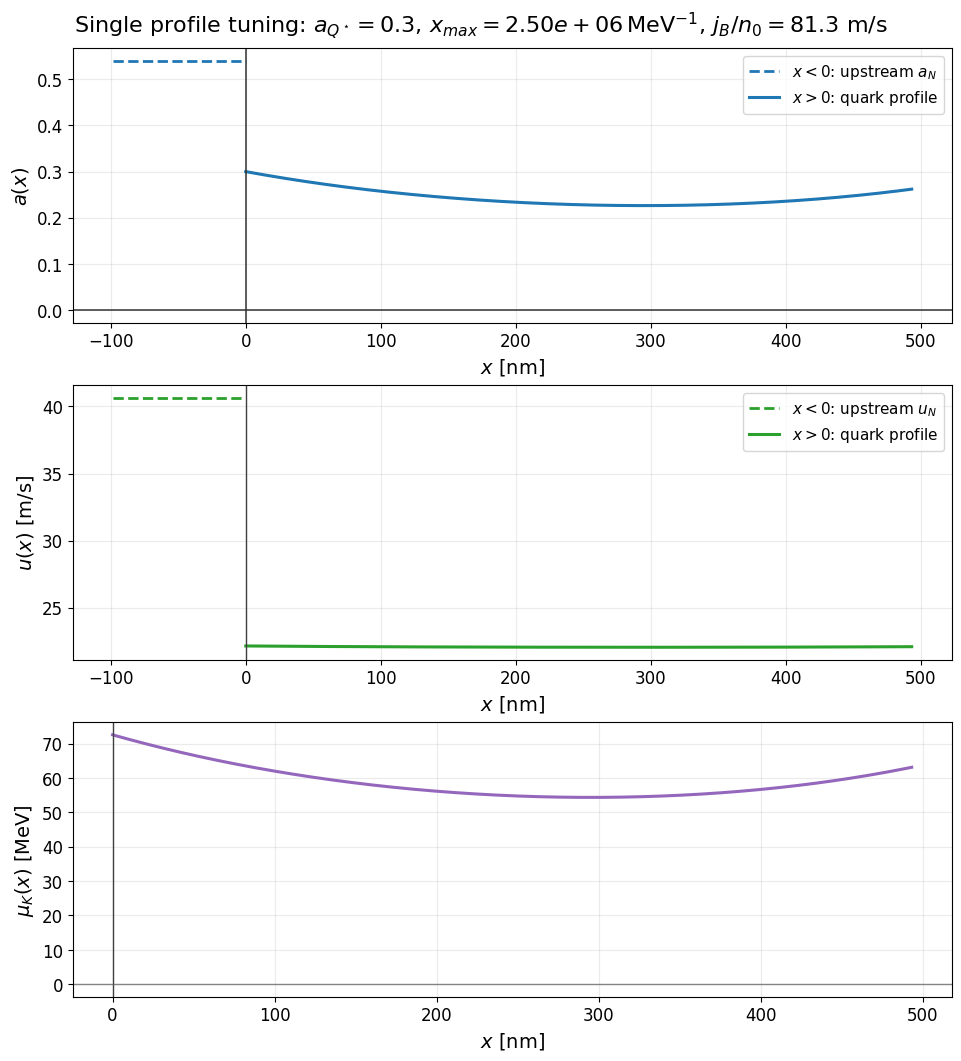

In [1]:
# SINGLE_AQSTAR_PROFILE_TUNING
# Tune one aQstar and x_max here. This cell is intentionally independent of the comparison cell above.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_steady_front_1d_aQstar

# -------------------------
# Tune these values
# -------------------------
T_single = 10.0
n0 = 0.16 * const.MeV_fm**3
nB_N_single = 2.0 * n0
B14_single = 180.0
ms_single = 0.0

aQstar_single = 0.30
x_max_single = 2.5e6  # Tune this directly. Example: 3.0e5, 1.0e6, 3.0e6
n_eval_single = 500

jB_guess_single = 0.5
jB_bounds_single = (0.02, 5.0)
root_tol_single = 1.0e-5
max_nfev_single = 40
verb_single = True  # False, True, or "full"

# Font controls
TitleFont = 16
LabelFont = 14
TickFont = 12
LegendFont = 11

# -------------------------
# Solve one fixed-aQstar profile
# -------------------------
res_single = solve_steady_front_1d_aQstar(
    T=T_single,
    nB_N=nB_N_single,
    B_one_forth=B14_single,
    aQstar=aQstar_single,
    ms=ms_single,
    x_max=x_max_single,
    n_eval=n_eval_single,
    root_tol=root_tol_single,
    max_nfev=max_nfev_single,
    jB_guess=jB_guess_single,
    jB_bounds=jB_bounds_single,
    return_profile=True,
    verb=verb_single,
)

print(f"success: {res_single.get('success')}")
print(f"message: {res_single.get('message', '')}")
print(f"aQstar: {res_single.get('aQstar', np.nan):.8g}")
print(f"jB: {res_single.get('jB', np.nan):.8g}")
print(f"jB/n0: {res_single.get('jB', np.nan)/n0*const.m_per_sec:.8g} m/s")
print(f"tail_norm: {res_single.get('tail_residual_norm', np.nan):.8g}")
print(f"tail_raw: {res_single.get('tail_residual', np.nan):.8g}")
print(f"a_end: {res_single.get('a_end', np.nan):.8g}")
print(f"q_end: {res_single.get('q_end', np.nan):.8g}")
print(f"muK_Qstar: {res_single.get('muK_Qstar', np.nan):.8g} MeV")
print(f"shooting_evals: {res_single.get('shooting_evals', 0)}")
print(f"ivp_rhs_calls: {res_single.get('ivp_rhs_calls', 0)}")
print(f"local_root_calls: {res_single.get('local_root_calls', 0)}")
print(f"local_fast_failures: {res_single.get('local_fast_failures', 0)}")

required = ['x', 'a', 'u', 'muK']
if not all(k in res_single for k in required):
    raise RuntimeError('Profile arrays were not returned. Check solver message above.')

# -------------------------
# Unit conversion and upstream extension
# -------------------------
x_nm = np.asarray(res_single['x'], dtype=float) * const.MeV_fm / 1.0e6
u_ms = np.asarray(res_single['u'], dtype=float) * const.m_per_sec
muK = np.asarray(res_single['muK'], dtype=float)
a_prof = np.asarray(res_single['a'], dtype=float)

left_extent_nm = max(0.2 * float(np.nanmax(x_nm)), 10.0) if len(x_nm) else 10.0
x_left_nm = np.linspace(-left_extent_nm, 0.0, 100)
a_left = np.full_like(x_left_nm, float(res_single.get('a_N', np.nan)), dtype=float)
u_left_ms = np.full_like(x_left_nm, float(res_single.get('u_N', np.nan)) * const.m_per_sec, dtype=float)

# -------------------------
# Plot: a(x), u(x), muK(x)
# -------------------------
fig, axes = plt.subplots(3, 1, figsize=(9.5, 10.5), constrained_layout=True)

axes[0].plot(x_left_nm, a_left, lw=2.0, ls='--', color='C0', label=r'$x<0$: upstream $a_N$')
axes[0].plot(x_nm, a_prof, lw=2.2, color='C0', label=r'$x>0$: quark profile')
axes[0].axvline(0.0, color='0.20', lw=1.1)
axes[0].axhline(0.0, color='0.20', lw=1.1)
axes[0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
axes[0].legend(fontsize=LegendFont)

axes[1].plot(x_left_nm, u_left_ms, lw=2.0, ls='--', color='C2', label=r'$x<0$: upstream $u_N$')
axes[1].plot(x_nm, u_ms, lw=2.2, color='C2', label=r'$x>0$: quark profile')
axes[1].axvline(0.0, color='0.25', lw=1.0)
axes[1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
axes[1].legend(fontsize=LegendFont)

axes[2].plot(x_nm, muK, lw=2.2, color='C4')
axes[2].axvline(0.0, color='0.25', lw=1.0)
axes[2].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[2].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)

for ax in axes:
    ax.set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=TickFont)

fig.suptitle(
    rf"Single profile tuning: $a_{{Q^\star}}={aQstar_single:g}$, "
    rf"$x_{{max}}={x_max_single:.2e}\,\mathrm{{MeV}}^{{-1}}$, "
    rf"$j_B/n_0={res_single.get('jB', np.nan)/n0*const.m_per_sec:.3g}$ m/s",
    fontsize=TitleFont,
)
plt.show()


## Rescaled Single `aQstar` Profile Tuning

This cell tests `solve_steady_front_1d_aQstar_rescaled(...)` using the same parameter setting as the previous single-profile tuning cell.


shoot1d-rescaled jB=0.5, aQstar=0.3, tail_norm=(-1.86691), tail_raw=(-2.05715e-07), s_end=0.727468, x_end=4.21475e+06, ok=True
shoot1d-rescaled jB=0.333333, aQstar=0.3, tail_norm=(1.91931), tail_raw=(2.47392e-07), s_end=0.727468, x_end=3.84947e+06, ok=True
shoot1d-rescaled jB=0.333333, aQstar=0.3, tail_norm=(1.91931), tail_raw=(2.47392e-07), s_end=0.727468, x_end=3.84947e+06, ok=True
shoot1d-rescaled jB=0.5, aQstar=0.3, tail_norm=(-1.86691), tail_raw=(-2.05715e-07), s_end=0.727468, x_end=4.21475e+06, ok=True
shoot1d-rescaled jB=0.409395, aQstar=0.3, tail_norm=(0.659227), tail_raw=(1.78519e-08), s_end=0.727468, x_end=4.013e+06, ok=True
shoot1d-rescaled jB=0.431322, aQstar=0.3, tail_norm=(-0.961251), tail_raw=(-2.88558e-08), s_end=0.727468, x_end=4.06114e+06, ok=True
shoot1d-rescaled jB=0.418178, aQstar=0.3, tail_norm=(-0.0679865), tail_raw=(-1.2244e-09), s_end=0.727468, x_end=4.03222e+06, ok=True
shoot1d-rescaled jB=0.417349, aQstar=0.3, tail_norm=(0.0308815), tail_raw=(5.48465e-10), s_

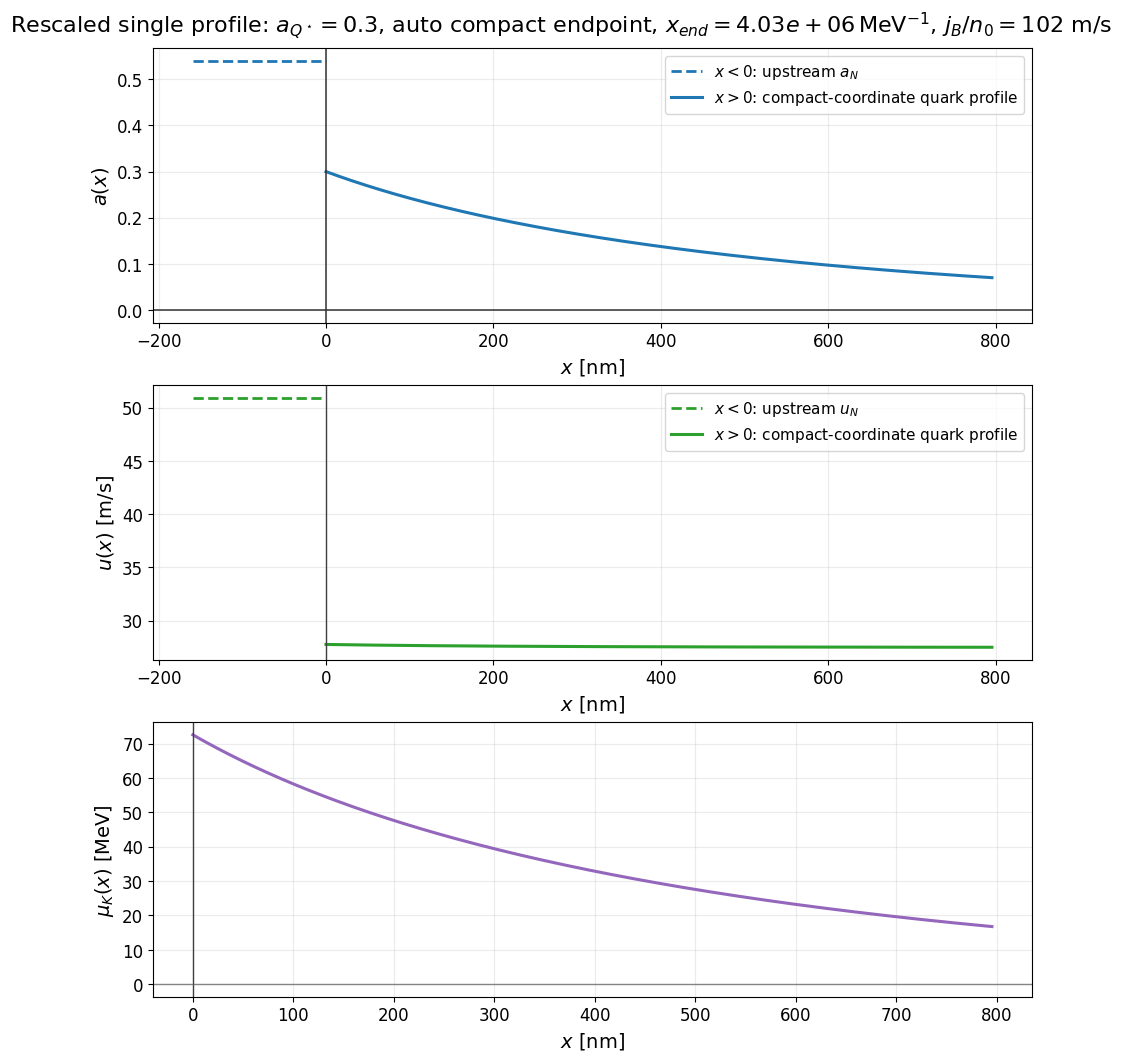

In [12]:
# SINGLE_AQSTAR_PROFILE_TUNING_RESCALED
# Test the compact-coordinate 1D solver with the same parameters as the finite-x single-profile cell above.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_steady_front_1d_aQstar_rescaled

# -------------------------
# Same parameter setting as the previous single-profile cell
# -------------------------
T_rescaled = 10.0
n0 = 0.16 * const.MeV_fm**3
nB_N_rescaled = 2.0 * n0
B14_rescaled = 180.0
ms_rescaled = 0.0

aQstar_rescaled = 0.30
x_max_rescaled = None  # Tests the fixed x_max=None path. Set a number like 2.5e6 to force a physical cutoff.
n_eval_rescaled = 500

jB_guess_rescaled = 0.5
jB_bounds_rescaled = (0.02, 5.0)
root_tol_rescaled = 1.0e-5
max_nfev_rescaled = 40
verb_rescaled = True  # False, True, or "full"

# Compact-coordinate controls
tail_eps_rescaled = 1.0e-8          # hard cap: s_end <= 1 - tail_eps
kappa_factor_rescaled = 1.0        # kappa = kappa_factor / lambda
compact_tail_lengths_rescaled = 1.3  # used only when x_max_rescaled is None

# Font controls
TitleFont = 16
LabelFont = 14
TickFont = 12
LegendFont = 11

# -------------------------
# Solve one fixed-aQstar profile with compact coordinate
# -------------------------
res_rescaled = solve_steady_front_1d_aQstar_rescaled(
    T=T_rescaled,
    nB_N=nB_N_rescaled,
    B_one_forth=B14_rescaled,
    aQstar=aQstar_rescaled,
    ms=ms_rescaled,
    x_max=x_max_rescaled,
    n_eval=n_eval_rescaled,
    root_tol=root_tol_rescaled,
    max_nfev=max_nfev_rescaled,
    jB_guess=jB_guess_rescaled,
    jB_bounds=jB_bounds_rescaled,
    tail_eps=tail_eps_rescaled,
    kappa_factor=kappa_factor_rescaled,
    compact_tail_lengths=compact_tail_lengths_rescaled,
    return_profile=True,
    verb=verb_rescaled,
)

print(f"success: {res_rescaled.get('success')}")
print(f"message: {res_rescaled.get('message', '')}")
print(f"aQstar: {res_rescaled.get('aQstar', np.nan):.8g}")
print(f"jB: {res_rescaled.get('jB', np.nan):.8g}")
print(f"jB/n0: {res_rescaled.get('jB', np.nan)/n0*const.m_per_sec:.8g} m/s")
print(f"tail_norm: {res_rescaled.get('tail_residual_norm', np.nan):.8g}")
print(f"tail_raw: {res_rescaled.get('tail_residual', np.nan):.8g}")
print(f"a_end: {res_rescaled.get('a_end', np.nan):.8g}")
print(f"q_end: {res_rescaled.get('q_end', np.nan):.8g}")
print(f"muK_Qstar: {res_rescaled.get('muK_Qstar', np.nan):.8g} MeV")
print(f"lambda: {res_rescaled.get('lambda', np.nan):.8g}")
print(f"kappa: {res_rescaled.get('kappa', np.nan):.8g} MeV^-1")
print(f"compact_tail_lengths: {res_rescaled.get('compact_tail_lengths', np.nan):.8g}")
print(f"s_end: {res_rescaled.get('s_end', np.nan):.8g}")
print(f"x_end: {res_rescaled.get('x_end', np.nan):.8g} MeV^-1")
print(f"shooting_evals: {res_rescaled.get('shooting_evals', 0)}")
print(f"ivp_rhs_calls: {res_rescaled.get('ivp_rhs_calls', 0)}")
print(f"local_root_calls: {res_rescaled.get('local_root_calls', 0)}")
print(f"local_fast_failures: {res_rescaled.get('local_fast_failures', 0)}")

required = ['x', 'a', 'u', 'muK']
if not all(k in res_rescaled for k in required):
    raise RuntimeError('Profile arrays were not returned. Check solver message above.')

# -------------------------
# Unit conversion and upstream extension
# -------------------------
x_nm = np.asarray(res_rescaled['x'], dtype=float) * const.MeV_fm / 1.0e6
u_ms = np.asarray(res_rescaled['u'], dtype=float) * const.m_per_sec
muK = np.asarray(res_rescaled['muK'], dtype=float)
a_prof = np.asarray(res_rescaled['a'], dtype=float)

left_extent_nm = max(0.2 * float(np.nanmax(x_nm)), 10.0) if len(x_nm) else 10.0
x_left_nm = np.linspace(-left_extent_nm, 0.0, 100)
a_left = np.full_like(x_left_nm, float(res_rescaled.get('a_N', np.nan)), dtype=float)
u_left_ms = np.full_like(x_left_nm, float(res_rescaled.get('u_N', np.nan)) * const.m_per_sec, dtype=float)

# -------------------------
# Plot: a(x), u(x), muK(x)
# -------------------------
fig, axes = plt.subplots(3, 1, figsize=(9.5, 10.5), constrained_layout=True)

axes[0].plot(x_left_nm, a_left, lw=2.0, ls='--', color='C0', label=r'$x<0$: upstream $a_N$')
axes[0].plot(x_nm, a_prof, lw=2.2, color='C0', label=r'$x>0$: compact-coordinate quark profile')
axes[0].axvline(0.0, color='0.20', lw=1.1)
axes[0].axhline(0.0, color='0.20', lw=1.1)
axes[0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
axes[0].legend(fontsize=LegendFont)

axes[1].plot(x_left_nm, u_left_ms, lw=2.0, ls='--', color='C2', label=r'$x<0$: upstream $u_N$')
axes[1].plot(x_nm, u_ms, lw=2.2, color='C2', label=r'$x>0$: compact-coordinate quark profile')
axes[1].axvline(0.0, color='0.25', lw=1.0)
axes[1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
axes[1].legend(fontsize=LegendFont)

axes[2].plot(x_nm, muK, lw=2.2, color='C4')
axes[2].axvline(0.0, color='0.25', lw=1.0)
axes[2].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[2].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)

for ax in axes:
    ax.set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=TickFont)

xmax_label = 'auto compact endpoint' if x_max_rescaled is None else rf'$x_{{max}}={x_max_rescaled:.2e}\,\mathrm{{MeV}}^{{-1}}$'
fig.suptitle(
    rf"Rescaled single profile: $a_{{Q^\star}}={aQstar_rescaled:g}$, "
    + xmax_label
    + rf", $x_{{end}}={res_rescaled.get('x_end', np.nan):.2e}\,\mathrm{{MeV}}^{{-1}}$, "
    + rf"$j_B/n_0={res_rescaled.get('jB', np.nan)/n0*const.m_per_sec:.3g}$ m/s",
    fontsize=TitleFont,
)
plt.show()


## BVP Rescaled Single `aQstar` Profile Tuning

This cell tests `solve_steady_front_1d_aQstar_rescale_bvp(...)` using the same parameter setting as the previous rescaled single-profile tuning cell. It uses `tail_eps` to truncate the compact coordinate and does not use `compact_tail_lengths`.


bvp jB=1.63548, aQstar=0.6, tail_norm=4.1293e-05, status=0, success=True
success: True
message: Compact BVP steady-front solve converged
bvp_status: 0
bvp_message: The algorithm converged to the desired accuracy.
bvp_niter: 1
bvp_nodes: 500
aQstar: 0.6
jB: 1.6354802
jB/n0: 398.829 m/s
tail_norm: 4.1293027e-05
tail_raw: 5.7787772e-20
a_end: 3.2098508e-09
q_end: -1.3993981e-15
muK_Qstar: 154.04955 MeV
lambda: 1.6396225e-07
kappa: 6098964.8 MeV^-1
tail_eps: 1e-08
s_end: 0.99999999
x_end: 1.1234708e+08 MeV^-1
global_state_builds: 16
bvp_ode_calls: 49
bvp_bc_calls: 30
local_root_calls: 124695
local_state_failures: 90


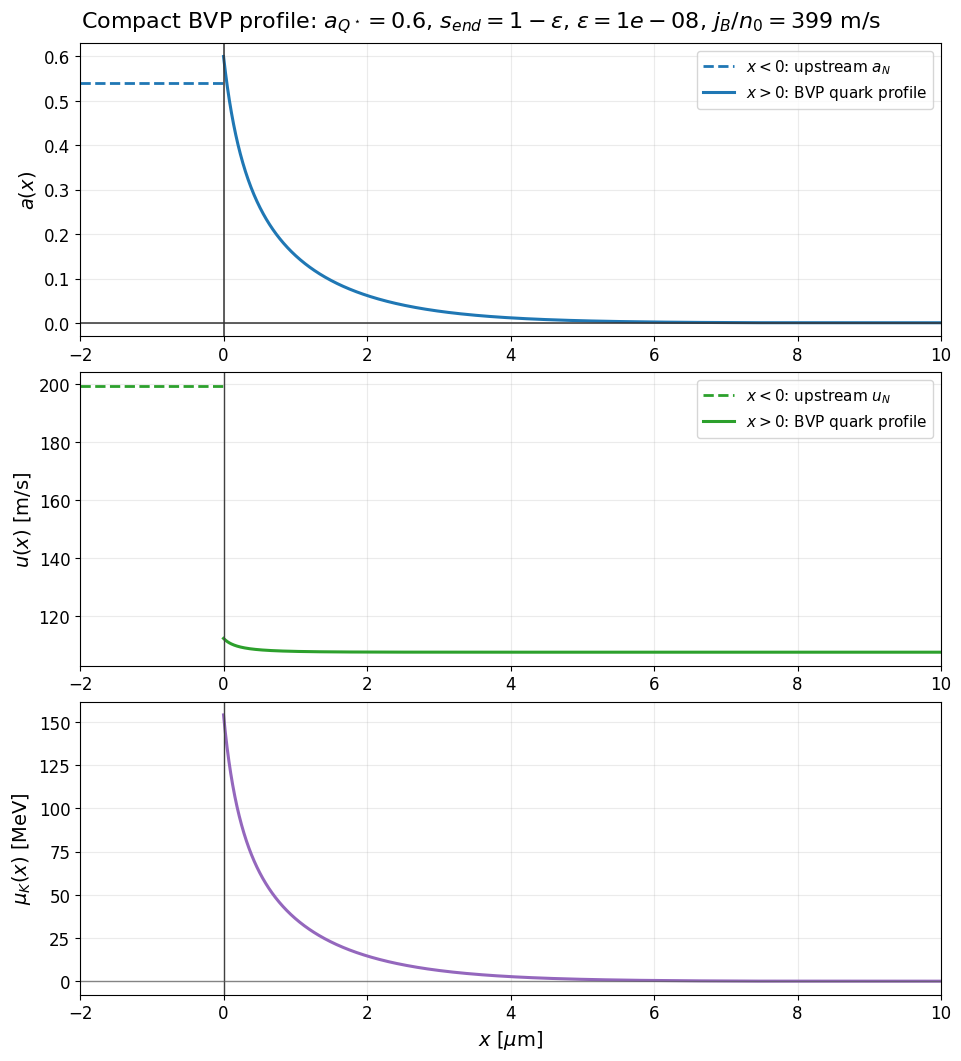

In [3]:
# SINGLE_AQSTAR_PROFILE_TUNING_RESCALE_BVP
# Test the compact-coordinate BVP solver with the same parameters as the previous rescaled single-profile cell.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_steady_front_1d_aQstar_rescale_bvp

# -------------------------
# Same parameter setting as the previous rescaled single-profile cell
# -------------------------
T_bvp = 10
n0 = 0.16 * const.MeV_fm**3
nB_N_bvp = 2.0 * n0
B14_bvp = 180.0
ms_bvp = 0.0

aQstar_bvp = 0.6
n_mesh_bvp = 500

jB_guess_bvp = 0.5
jB_bounds_bvp = (1e-4, 5.0)
tol_bvp = 1.0e-4
max_nodes_bvp = 50000
verb_bvp = True  # False, True, or "full"

# Compact-coordinate controls for the BVP solver.
# The BVP path does not use compact_tail_lengths. Tune tail_eps to choose s_end = 1 - tail_eps.
tail_eps_bvp = 1.0e-8
kappa_factor_bvp = 1.0

# Font controls
TitleFont = 16
LabelFont = 14
TickFont = 12
LegendFont = 11

# -------------------------
# Solve one fixed-aQstar profile with compact-coordinate BVP
# -------------------------
res_bvp = solve_steady_front_1d_aQstar_rescale_bvp(
    T=T_bvp,
    nB_N=nB_N_bvp,
    B_one_forth=B14_bvp,
    aQstar=aQstar_bvp,
    ms=ms_bvp,
    tail_eps=tail_eps_bvp,
    n_mesh=n_mesh_bvp,
    tol_bvp=tol_bvp,
    max_nodes=max_nodes_bvp,
    jB_guess=jB_guess_bvp,
    jB_bounds=jB_bounds_bvp,
    kappa_factor=kappa_factor_bvp,
    return_profile=True,
    verb=verb_bvp,
)

print(f"success: {res_bvp.get('success')}")
print(f"message: {res_bvp.get('message', '')}")
print(f"bvp_status: {res_bvp.get('bvp_status', np.nan)}")
print(f"bvp_message: {res_bvp.get('bvp_message', '')}")
print(f"bvp_niter: {res_bvp.get('bvp_niter', np.nan)}")
print(f"bvp_nodes: {res_bvp.get('bvp_nodes', np.nan)}")
print(f"aQstar: {res_bvp.get('aQstar', np.nan):.8g}")
print(f"jB: {res_bvp.get('jB', np.nan):.8g}")
print(f"jB/n0: {res_bvp.get('jB', np.nan)/n0*const.m_per_sec:.8g} m/s")
print(f"tail_norm: {res_bvp.get('tail_residual_norm', np.nan):.8g}")
print(f"tail_raw: {res_bvp.get('tail_residual', np.nan):.8g}")
print(f"a_end: {res_bvp.get('a_end', np.nan):.8g}")
print(f"q_end: {res_bvp.get('q_end', np.nan):.8g}")
print(f"muK_Qstar: {res_bvp.get('muK_Qstar', np.nan):.8g} MeV")
print(f"lambda: {res_bvp.get('lambda', np.nan):.8g}")
print(f"kappa: {res_bvp.get('kappa', np.nan):.8g} MeV^-1")
print(f"tail_eps: {res_bvp.get('tail_eps', np.nan):.8g}")
print(f"s_end: {res_bvp.get('s_end', np.nan):.8g}")
print(f"x_end: {res_bvp.get('x_end', np.nan):.8g} MeV^-1")
print(f"global_state_builds: {res_bvp.get('global_state_builds', 0)}")
print(f"bvp_ode_calls: {res_bvp.get('bvp_ode_calls', 0)}")
print(f"bvp_bc_calls: {res_bvp.get('bvp_bc_calls', 0)}")
print(f"local_root_calls: {res_bvp.get('local_root_calls', 0)}")
print(f"local_state_failures: {res_bvp.get('local_state_failures', 0)}")

required = ['x', 'a', 'u', 'muK']
if not all(k in res_bvp for k in required):
    raise RuntimeError('Profile arrays were not returned. Check solver message above.')

# -------------------------
# Unit conversion and upstream extension
# -------------------------
x_nm = np.asarray(res_bvp['x'], dtype=float) * const.MeV_fm / 1.0e6
x_um = x_nm / 1000.0
u_ms = np.asarray(res_bvp['u'], dtype=float) * const.m_per_sec
muK = np.asarray(res_bvp['muK'], dtype=float)
a_prof = np.asarray(res_bvp['a'], dtype=float)

x_left_um = np.linspace(-2.0, 0.0, 100)
a_left = np.full_like(x_left_um, float(res_bvp.get('a_N', np.nan)), dtype=float)
u_left_ms = np.full_like(x_left_um, float(res_bvp.get('u_N', np.nan)) * const.m_per_sec, dtype=float)

# -------------------------
# Plot: a(x), u(x), muK(x)
# -------------------------
fig, axes = plt.subplots(3, 1, figsize=(9.5, 10.5), constrained_layout=True)

axes[0].plot(x_left_um, a_left, lw=2.0, ls='--', color='C0', label=r'$x<0$: upstream $a_N$')
axes[0].plot(x_um, a_prof, lw=2.2, color='C0', label=r'$x>0$: BVP quark profile')
axes[0].axvline(0.0, color='0.20', lw=1.1)
axes[0].axhline(0.0, color='0.20', lw=1.1)
axes[0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
axes[0].legend(fontsize=LegendFont)

axes[1].plot(x_left_um, u_left_ms, lw=2.0, ls='--', color='C2', label=r'$x<0$: upstream $u_N$')
axes[1].plot(x_um, u_ms, lw=2.2, color='C2', label=r'$x>0$: BVP quark profile')
axes[1].axvline(0.0, color='0.25', lw=1.0)
axes[1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
axes[1].legend(fontsize=LegendFont)

axes[2].plot(x_um, muK, lw=2.2, color='C4')
axes[2].axvline(0.0, color='0.25', lw=1.0)
axes[2].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[2].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)
axes[2].set_xlabel(r'$x$ [$\mu$m]', fontsize=LabelFont)

for ax in axes:
    ax.set_xlim(-2.0, 10.0)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

fig.suptitle(
    rf'Compact BVP profile: $a_{{Q^\star}}={aQstar_bvp:g}$, '
    rf'$s_{{end}}=1-\epsilon$, $\epsilon={tail_eps_bvp:.0e}$, '
    rf'$j_B/n_0={res_bvp.get("jB", np.nan)/n0*const.m_per_sec:.3g}$ m/s',
    fontsize=TitleFont,
)
plt.show()


## 6Apr BVP Cluster Results

Load the latest `steady_front_bvp_run_*` folder from `new_paper_calculations/26-04-06`, plot the initial guess to final BVP result in the `(jB/n0, aQstar)` plane, and compare representative saved profiles.


Using requested 6Apr BVP run: steady_front_bvp_run_20260407_151939
Total points: 10
Successful finite BVP points with npz: 8
Successful BVP points with profile arrays: 8
Failed but finite BVP points: 0
Failed before finite final jB: 2
Run aQstar values: [0.05, 0.11666666666666667, 0.18333333333333335, 0.25, 0.31666666666666665, 0.3833333333333333, 0.45, 0.5166666666666667, 0.5833333333333334, 0.6]
Successful point indices: [1, 2, 3, 4, 5, 6, 7, 8]
Profile-available point indices: [1, 2, 3, 4, 5, 6, 7, 8]
jB guess strategy: linear-aQstar slope= 1.82 bounds= [1e-05, 50.0]
Upstream composition reference: a_N = 0.539649
Saved parameter-plane plot to: /Users/janshao/NSM_related/new_paper_calculations/26-04-06/steady_front_bvp_run_20260407_151939_bvp_parameter_plane.pdf


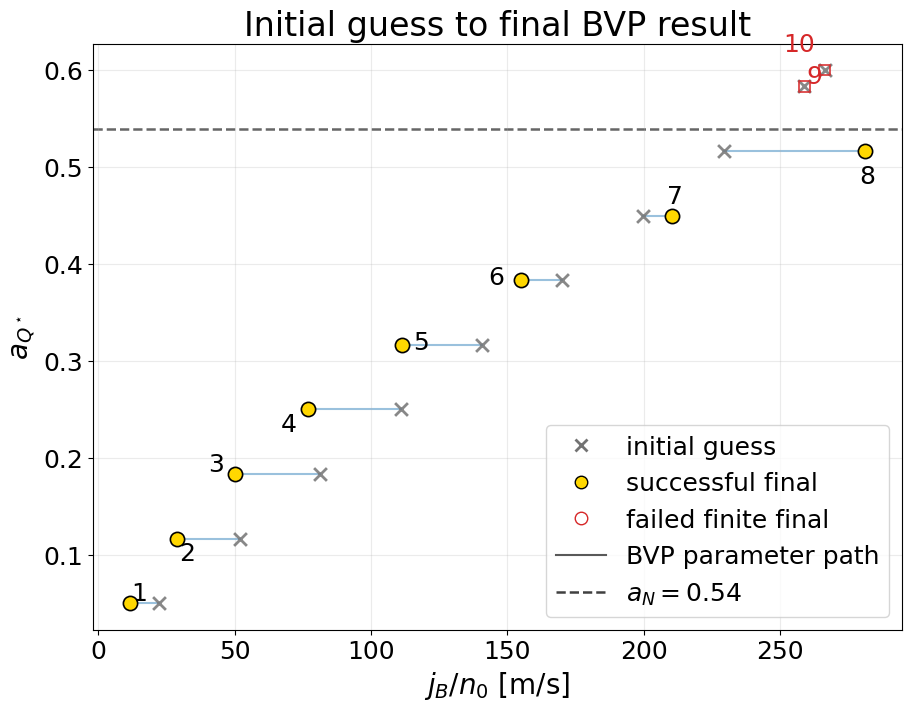

Representative profile points:
  point  1: success=True, aQstar=0.05, jB=0.0472672, jB/n0=11.5266 m/s, tail_norm=3.810e-05, muK_Qstar=11.8898 MeV
  point  3: success=True, aQstar=0.183333, jB=0.205589, jB/n0=50.1351 m/s, tail_norm=8.613e-05, muK_Qstar=43.8515 MeV
  point  6: success=True, aQstar=0.383333, jB=0.635221, jB/n0=154.905 m/s, tail_norm=-1.164e-06, muK_Qstar=93.7727 MeV
  point  8: success=True, aQstar=0.516667, jB=1.15267, jB/n0=281.092 m/s, tail_norm=-2.984e-07, muK_Qstar=129.734 MeV
Saved profile-summary plot to: /Users/janshao/NSM_related/new_paper_calculations/26-04-06/steady_front_bvp_run_20260407_151939_bvp_profile_summary.pdf


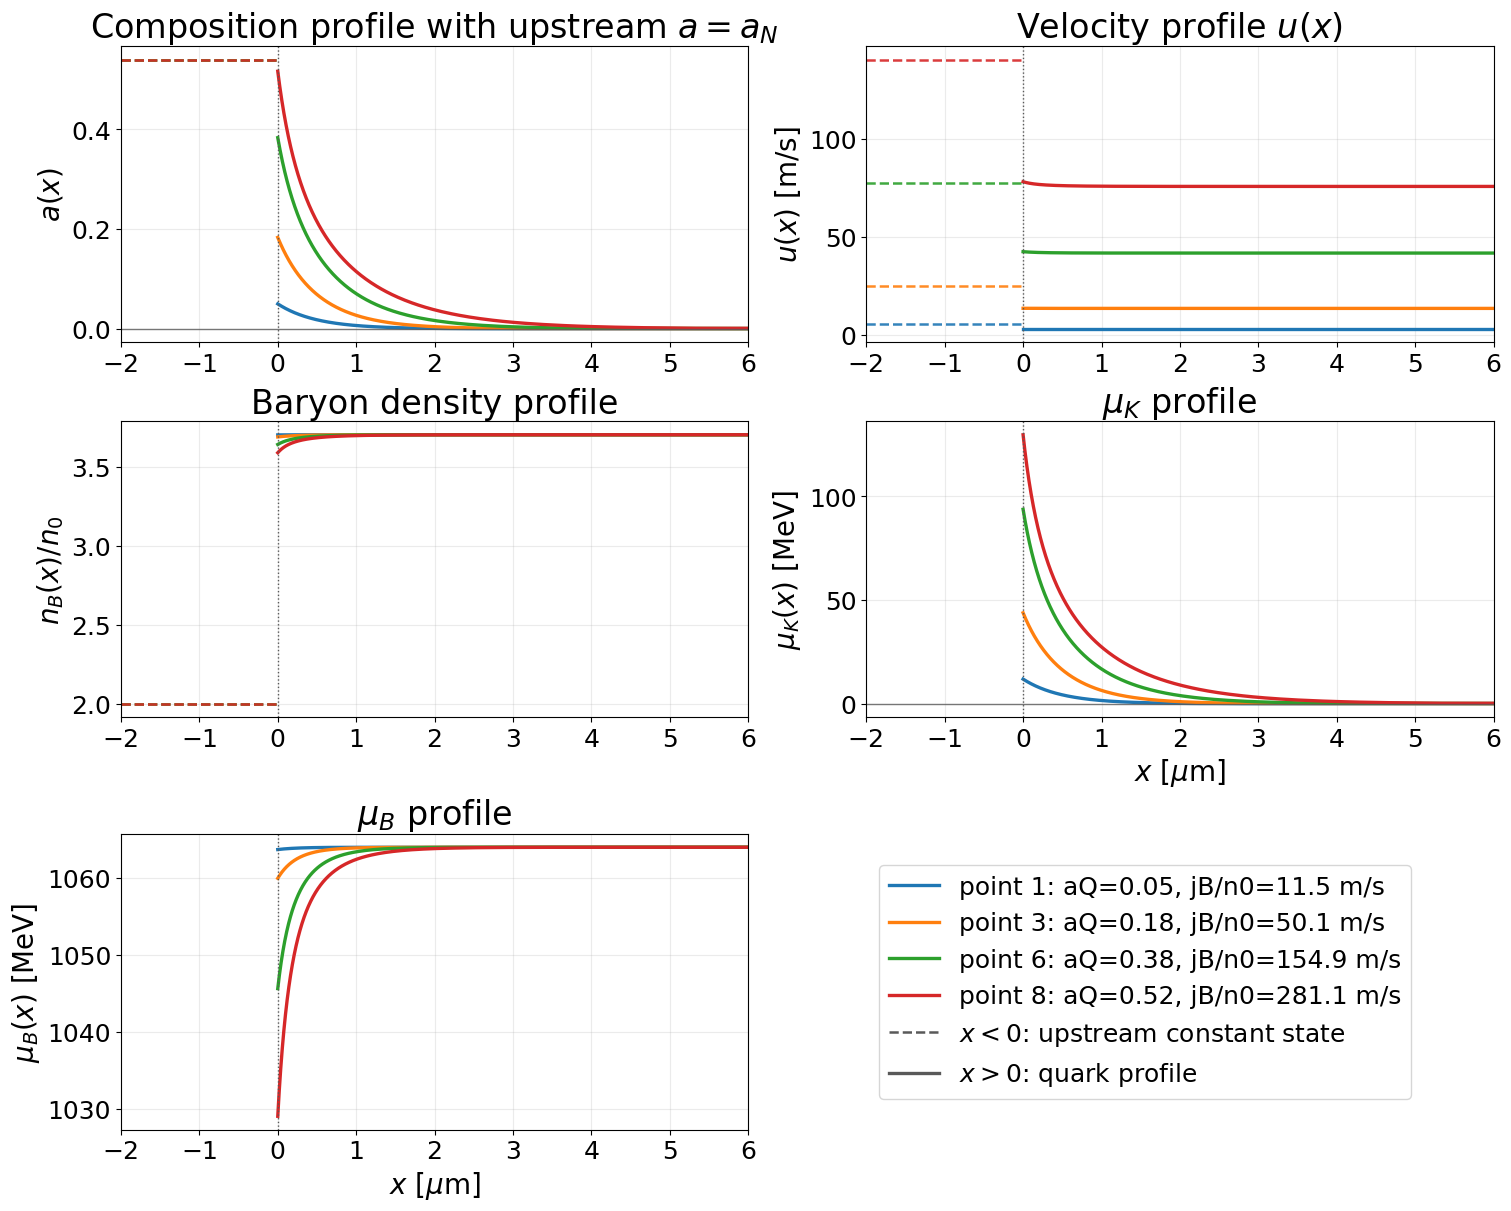

In [5]:
# BVP_CLUSTER_6APR_VISUALIZATION
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

repo_root = Path('/Users/janshao/NSM_related')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import RMFsolver.constants as const

# -------------------------
# Tunable plotting controls
# -------------------------
TitleFont = 24
LabelFont = 20
TickFont = 18
LegendFont = 18
AnnotFont = 18

profile_xlim_um = (-2.0, 6.0)
max_profile_curves = 4
show_failed_finite_results = True

results_root = repo_root / 'new_paper_calculations' / '6Apr'
requested_run_name = 'steady_front_bvp_run_20260407_151939'
run_dir = results_root / requested_run_name
if not run_dir.is_dir():
    raise RuntimeError(f'Requested BVP run folder not found: {run_dir}')
print(f'Using requested 6Apr BVP run: {run_dir.name}')

fig1_pdf = results_root / f'{run_dir.name}_bvp_parameter_plane.pdf'
fig2_pdf = results_root / f'{run_dir.name}_bvp_profile_summary.pdf'

config = json.loads((run_dir / 'run_config.json').read_text())
rows = [json.loads(line) for line in (run_dir / 'trial_summary.jsonl').read_text().splitlines() if line.strip()]
rows = sorted(rows, key=lambda r: int(r.get('point_index', 10**9)))

def finite_float(value):
    try:
        out = float(value)
    except Exception:
        return np.nan
    return out if np.isfinite(out) else np.nan

def local_npz_path(row):
    raw = str(row.get('npz_path', ''))
    if raw:
        candidate = run_dir / Path(raw).name
        if candidate.exists():
            return candidate
    matches = sorted(run_dir.glob(f"point_{int(row['point_index']):03d}__*.npz"))
    return matches[0] if matches else None

def npz_has_profile(path):
    if path is None or not Path(path).exists():
        return False
    try:
        with np.load(path) as data:
            needed = {'x', 'a', 'u', 'nB', 'muB', 'muK'}
            return needed.issubset(set(data.files))
    except Exception:
        return False

for row in rows:
    row['npz_path_local'] = local_npz_path(row)
    row['jB_float'] = finite_float(row.get('jB'))
    row['jB_guess_float'] = finite_float(row.get('jB_guess_initial', config.get('jB_guess', np.nan)))
    row['aQstar_float'] = finite_float(row.get('aQstar', row.get('aQstar_input')))
    row['a_N_float'] = finite_float(row.get('a_N'))
    row['tail_norm_float'] = finite_float(row.get('tail_residual_norm'))
    row['jB_ms'] = row['jB_float'] / (0.16 * const.MeV_fm**3) * const.m_per_sec if np.isfinite(row['jB_float']) else np.nan
    row['jB_guess_ms'] = row['jB_guess_float'] / (0.16 * const.MeV_fm**3) * const.m_per_sec if np.isfinite(row['jB_guess_float']) else np.nan

aN_values = [r['a_N_float'] for r in rows if np.isfinite(r.get('a_N_float', np.nan))]
aN_ref = float(np.nanmedian(aN_values)) if aN_values else np.nan

success_rows = [r for r in rows if bool(r.get('success')) and r['npz_path_local'] is not None and np.isfinite(r['jB_float'])]
profile_rows = [r for r in success_rows if npz_has_profile(r['npz_path_local'])]
finite_rows = [r for r in rows if np.isfinite(r['jB_float'])]
failed_rows = [r for r in finite_rows if not bool(r.get('success'))]
no_final_rows = [r for r in rows if not np.isfinite(r['jB_float']) and np.isfinite(r['jB_guess_ms'])]
print(f'Total points: {len(rows)}')
print(f'Successful finite BVP points with npz: {len(success_rows)}')
print(f'Successful BVP points with profile arrays: {len(profile_rows)}')
print(f'Failed but finite BVP points: {len(failed_rows)}')
print(f'Failed before finite final jB: {len(no_final_rows)}')
print('Run aQstar values:', [finite_float(r.get('aQstar', r.get('aQstar_input'))) for r in rows])
print('Successful point indices:', [r['point_index'] for r in success_rows])
print('Profile-available point indices:', [r['point_index'] for r in profile_rows])
print('jB guess strategy:', config.get('jB_guess_mode'), 'slope=', config.get('jB_aQstar_slope'), 'bounds=', config.get('jB_bounds'))
if np.isfinite(aN_ref):
    print(f'Upstream composition reference: a_N = {aN_ref:.6g}')

# -------------------------
# Helper: non-overlapping trial labels
# -------------------------
def annotate_nonoverlap(ax, xs, ys, labels, fontsize=AnnotFont, color='black'):
    anns = []
    base_offsets = [(7, 7), (7, -11), (-14, 7), (-14, -11), (14, 2), (-18, 2), (2, 14), (2, -18)]
    for i, (x, y, label) in enumerate(zip(xs, ys, labels)):
        if not (np.isfinite(x) and np.isfinite(y)):
            continue
        ann = ax.annotate(
            str(label),
            xy=(x, y),
            xytext=base_offsets[i % len(base_offsets)],
            textcoords='offset points',
            fontsize=fontsize,
            color=color,
            ha='center',
            va='center',
            clip_on=False,
        )
        anns.append(ann)
    fig = ax.figure
    for _ in range(120):
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        boxes = [ann.get_window_extent(renderer).expanded(1.08, 1.18) for ann in anns]
        moved = False
        for i in range(len(anns)):
            for j in range(i + 1, len(anns)):
                if boxes[i].overlaps(boxes[j]):
                    dx, dy = anns[j].get_position()
                    direction = 1 if (j % 2 == 0) else -1
                    anns[j].set_position((dx + 5 * direction, dy + 6))
                    moved = True
        if not moved:
            break
    return anns

# -------------------------
# Figure 1: initial guess to final BVP result in (jB, aQstar)
# -------------------------
fig1, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)

if np.isfinite(aN_ref):
    ax.axhline(aN_ref, color='0.25', lw=1.8, ls='--', alpha=0.8, zorder=0)

for row in rows:
    x0 = row['jB_guess_ms']
    y0 = row['aQstar_float']
    x1 = row['jB_ms']
    y1 = row['aQstar_float']
    if np.isfinite(x0) and np.isfinite(y0):
        ax.scatter(x0, y0, marker='x', s=85, lw=2.0, color='0.45', alpha=0.85, zorder=3)
    if np.isfinite(x0) and np.isfinite(x1) and np.isfinite(y0):
        color = 'C0' if row.get('success') else 'C3'
        ax.plot([x0, x1], [y0, y1], lw=1.5, color=color, alpha=0.45, zorder=1)
    if np.isfinite(x1) and np.isfinite(y1):
        if row.get('success'):
            ax.scatter(x1, y1, marker='o', s=105, facecolor='gold', edgecolor='black', lw=1.2, zorder=4)
        elif show_failed_finite_results:
            ax.scatter(x1, y1, marker='o', s=90, facecolor='none', edgecolor='C3', lw=1.8, zorder=4)
    elif np.isfinite(x0) and np.isfinite(y0):
        # No finite final jB: mark the failed trial at its initial guess row.
        ax.scatter(x0, y0, marker='s', s=55, facecolor='none', edgecolor='C3', lw=1.4, alpha=0.8, zorder=4)

label_rows = [r for r in rows if np.isfinite(r['jB_ms'])]
annotate_nonoverlap(
    ax,
    [r['jB_ms'] for r in label_rows],
    [r['aQstar_float'] for r in label_rows],
    [r['point_index'] for r in label_rows],
    fontsize=AnnotFont,
)
# Label no-finite-final cases near the initial guess, in red.
annotate_nonoverlap(
    ax,
    [r['jB_guess_ms'] for r in no_final_rows],
    [r['aQstar_float'] for r in no_final_rows],
    [r['point_index'] for r in no_final_rows],
    fontsize=AnnotFont,
    color='C3',
)

legend_handles = [
    Line2D([0], [0], marker='x', color='0.45', lw=0, markersize=9, markeredgewidth=2, label='initial guess'),
    Line2D([0], [0], marker='o', color='black', markerfacecolor='gold', lw=0, markersize=9, label='successful final'),
    Line2D([0], [0], marker='o', color='C3', markerfacecolor='none', lw=0, markersize=9, label='failed finite final'),
    Line2D([0], [0], color='0.35', lw=1.5, label='BVP parameter path'),
]
if np.isfinite(aN_ref):
    legend_handles.append(Line2D([0], [0], color='0.25', lw=1.8, ls='--', label=rf'$a_N={aN_ref:.3g}$'))
ax.legend(handles=legend_handles, fontsize=LegendFont, loc='best')
ax.set_title('Initial guess to final BVP result', fontsize=TitleFont)
ax.set_xlabel(r'$j_B/n_0$ [m/s]', fontsize=LabelFont)
ax.set_ylabel(r'$a_{Q^\star}$', fontsize=LabelFont)
ax.grid(alpha=0.25)
ax.tick_params(labelsize=TickFont)
fig1.savefig(fig1_pdf, bbox_inches='tight')
print(f'Saved parameter-plane plot to: {fig1_pdf}')
plt.show()

# -------------------------
# Figure 2: representative profiles
# -------------------------
if not profile_rows:
    print('No successful BVP profiles with arrays to plot. The first figure still shows scalar BVP results, if any.')
else:
    # Select up to max_profile_curves successful profiles spanning aQstar.
    success_sorted = sorted(profile_rows, key=lambda r: r['aQstar_float'])
    if len(success_sorted) <= max_profile_curves:
        selected_rows = success_sorted
    else:
        idx = np.unique(np.round(np.linspace(0, len(success_sorted) - 1, max_profile_curves)).astype(int))
        selected_rows = [success_sorted[i] for i in idx]

    print('Representative profile points:')
    for r in selected_rows:
        print(
            f"  point {r['point_index']:2d}: success={r['success']}, "
            f"aQstar={r['aQstar_float']:.6g}, jB={r['jB_float']:.6g}, "
            f"jB/n0={r['jB_ms']:.6g} m/s, tail_norm={r['tail_norm_float']:.3e}, "
            f"muK_Qstar={finite_float(r.get('muK_Qstar')):.6g} MeV"
        )

    fig2, axes = plt.subplots(3, 2, figsize=(15, 12), constrained_layout=True)
    colors = plt.get_cmap('tab10').colors
    handles = []
    x_left_um = np.linspace(profile_xlim_um[0], 0.0, 160)

    for i, row in enumerate(selected_rows):
        color = colors[i % len(colors)]
        label = (
            f"point {row['point_index']}: "
            f"aQ={row['aQstar_float']:.2f}, "
            f"jB/n0={row['jB_ms']:.1f} m/s"
        )
        handles.append(Line2D([0], [0], color=color, lw=2.4, label=label))
        with np.load(row['npz_path_local']) as data:
            x_um = np.asarray(data['x'], dtype=float) * const.MeV_fm / 1.0e9
            a_vals = np.asarray(data['a'], dtype=float)
            u_ms = np.asarray(data['u'], dtype=float) * const.m_per_sec
            nB_over_n0 = np.asarray(data['nB'], dtype=float) / (0.16 * const.MeV_fm**3)
            muK = np.asarray(data['muK'], dtype=float)
            muB = np.asarray(data['muB'], dtype=float)
            a_left = np.full_like(x_left_um, float(row['a_N']))
            u_left_ms = np.full_like(x_left_um, float(row['u_N']) * const.m_per_sec)
            nB_left_over_n0 = np.full_like(x_left_um, float(config['nB_factor']))

        axes[0, 0].plot(x_left_um, a_left, lw=1.8, ls='--', color=color, alpha=0.9)
        axes[0, 0].plot(x_um, a_vals, lw=2.4, color=color)
        axes[0, 1].plot(x_left_um, u_left_ms, lw=1.8, ls='--', color=color, alpha=0.9)
        axes[0, 1].plot(x_um, u_ms, lw=2.4, color=color)
        axes[1, 0].plot(x_left_um, nB_left_over_n0, lw=1.8, ls='--', color=color, alpha=0.9)
        axes[1, 0].plot(x_um, nB_over_n0, lw=2.4, color=color)
        axes[1, 1].plot(x_um, muK, lw=2.4, color=color)
        axes[2, 0].plot(x_um, muB, lw=2.4, color=color)

    axes[0, 0].set_title(r'Composition profile with upstream $a=a_N$', fontsize=TitleFont)
    axes[0, 1].set_title(r'Velocity profile $u(x)$', fontsize=TitleFont)
    axes[1, 0].set_title(r'Baryon density profile', fontsize=TitleFont)
    axes[1, 1].set_title(r'$\mu_K$ profile', fontsize=TitleFont)
    axes[2, 0].set_title(r'$\mu_B$ profile', fontsize=TitleFont)

    axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
    axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
    axes[1, 0].set_ylabel(r'$n_B(x) / n_0$', fontsize=LabelFont)
    axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)
    axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)
    axes[2, 0].set_xlabel(r'$x$ [$\mu$m]', fontsize=LabelFont)
    axes[1, 1].set_xlabel(r'$x$ [$\mu$m]', fontsize=LabelFont)

    for ax in axes.flat:
        ax.set_xlim(*profile_xlim_um)
        if ax is not axes[2, 1]:
            ax.axvline(0.0, color='0.35', lw=1.0, ls=':')
            ax.grid(alpha=0.25)
            ax.tick_params(labelsize=TickFont)
    axes[0, 0].axhline(0.0, color='0.35', lw=1.0, alpha=0.8)
    axes[1, 1].axhline(0.0, color='0.35', lw=1.0, alpha=0.8)

    style_handles = [
        Line2D([0], [0], color='0.35', lw=1.8, ls='--', label=r'$x<0$: upstream constant state'),
        Line2D([0], [0], color='0.35', lw=2.4, label=r'$x>0$: quark profile'),
    ]
    axes[2, 1].axis('off')
    axes[2, 1].legend(handles=handles + style_handles, fontsize=LegendFont, loc='center left')
    #fig2.suptitle(f'BVP profiles from {run_dir.name}', fontsize=TitleFont)
    fig2.savefig(fig2_pdf, bbox_inches='tight')
    print(f'Saved profile-summary plot to: {fig2_pdf}')
    plt.show()


## BVP Rescaled Single `aQstar` Profile Tuning with Closure Check

Run the latest compact-coordinate 1D BVP solver, visualize the returned profiles, and verify the local composition-closure residual point by point.


bvp jB=1.14915, aQstar=0.65, tail_norm=-1.56041e-05, status=0, success=True
success: True
message: Compact BVP steady-front solve converged
branch_label: muK-rich
bvp_status: 0
bvp_message: The algorithm converged to the desired accuracy.
bvp_niter: 1
bvp_nodes: 500
aQstar: 0.65
jB: 1.1491502
jB/n0: 280.23233 m/s
tail_norm: -1.5604061e-05
tail_raw: -3.2666704e-20
a_end: 5.8526819e-09
q_end: -2.0934745e-15
muK_Qstar: 172.62858 MeV
lambda: 1.6057508e-06
kappa: 622761.64 MeV^-1
tail_eps: 1e-08
s_end: 0.99999999
x_end: 11471693 MeV^-1
global_state_builds: 12
bvp_ode_calls: 37
bvp_bc_calls: 22
local_root_calls: 94829
local_state_failures: 2
closure_error_max (solver): 4.27435864e-15
max closure error (recomputed): 4.27435864e-15


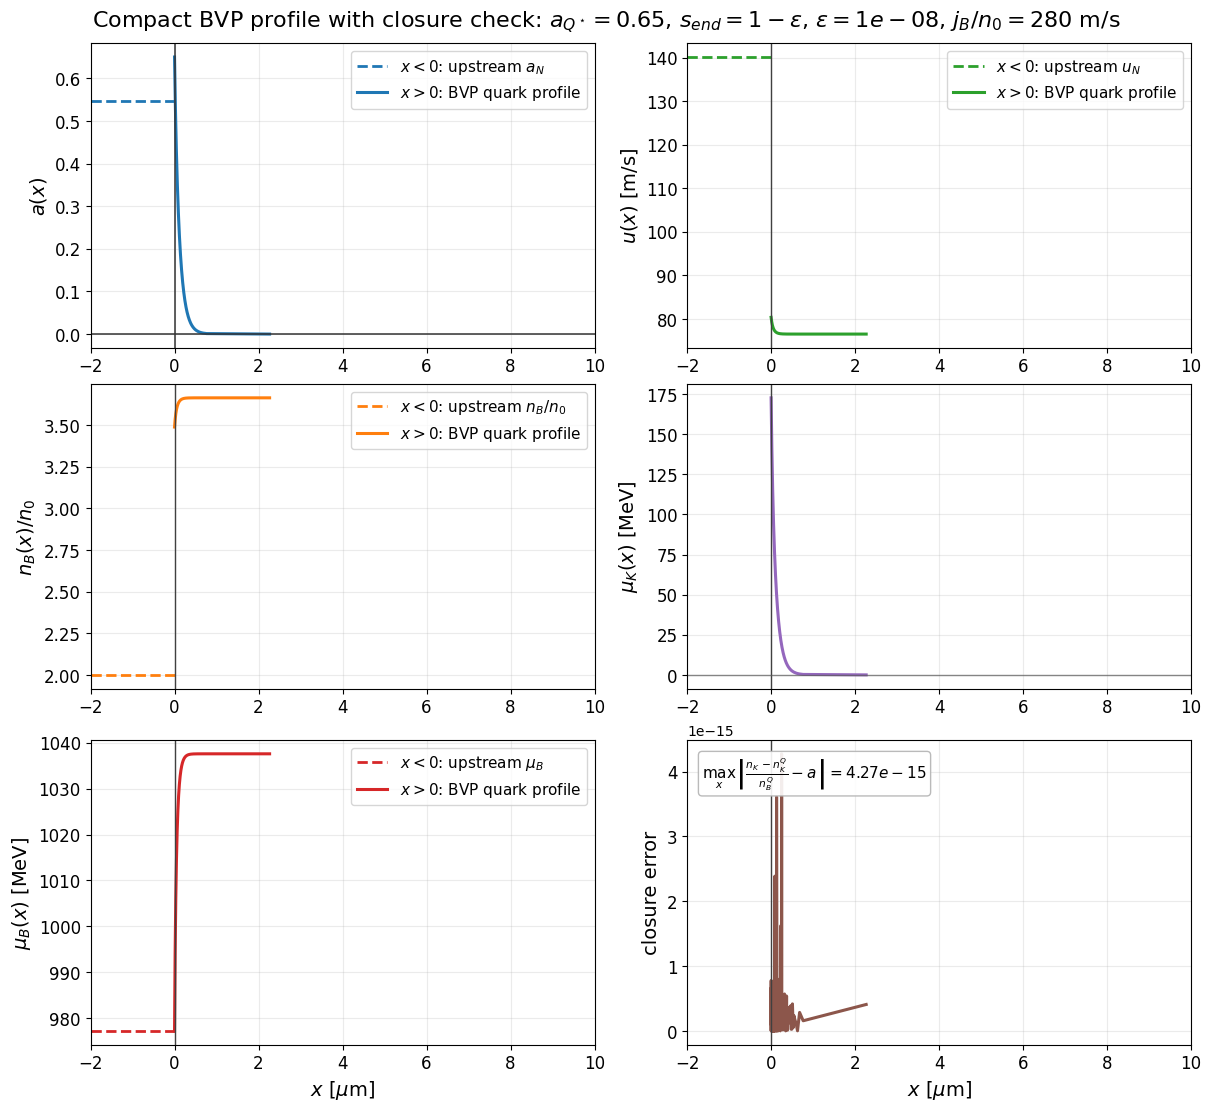

In [6]:
# SINGLE_AQSTAR_PROFILE_TUNING_RESCALE_BVP_CLOSURE_CHECK
# Test the compact-coordinate BVP solver and visualize the returned profiles together with
# the local composition-closure error.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.phase_velocity import nK_QM, solve_steady_front_1d_aQstar_rescale_bvp

# -------------------------
# Tunable inputs
# -------------------------
T_bvp_check = 30
n0 = 0.16 * const.MeV_fm**3
nB_N_bvp_check = 2.0 * n0
B14_bvp_check = 180.0
ms_bvp_check = 0.0

aQstar_bvp_check = 0.65
n_mesh_bvp_check = 500

jB_guess_bvp_check = 0.5
jB_bounds_bvp_check = (1e-4, 5.0)
tol_bvp_check = 1.0e-4
max_nodes_bvp_check = 50000
verb_bvp_check = True

# Compact-coordinate controls for the BVP solver.
tail_eps_bvp_check = 1.0e-8
kappa_factor_bvp_check = 1.0

# Font controls
TitleFont = 16
LabelFont = 14
TickFont = 12
LegendFont = 11

# -------------------------
# Solve one fixed-aQstar profile with compact-coordinate BVP
# -------------------------
res_bvp_check = solve_steady_front_1d_aQstar_rescale_bvp(
    T=T_bvp_check,
    nB_N=nB_N_bvp_check,
    B_one_forth=B14_bvp_check,
    aQstar=aQstar_bvp_check,
    ms=ms_bvp_check,
    tail_eps=tail_eps_bvp_check,
    n_mesh=n_mesh_bvp_check,
    tol_bvp=tol_bvp_check,
    max_nodes=max_nodes_bvp_check,
    jB_guess=jB_guess_bvp_check,
    jB_bounds=jB_bounds_bvp_check,
    kappa_factor=kappa_factor_bvp_check,
    return_profile=True,
    verb=verb_bvp_check,
)

print(f"success: {res_bvp_check.get('success')}")
print(f"message: {res_bvp_check.get('message', '')}")
print(f"branch_label: {res_bvp_check.get('branch_label', '')}")
print(f"bvp_status: {res_bvp_check.get('bvp_status', np.nan)}")
print(f"bvp_message: {res_bvp_check.get('bvp_message', '')}")
print(f"bvp_niter: {res_bvp_check.get('bvp_niter', np.nan)}")
print(f"bvp_nodes: {res_bvp_check.get('bvp_nodes', np.nan)}")
print(f"aQstar: {res_bvp_check.get('aQstar', np.nan):.8g}")
print(f"jB: {res_bvp_check.get('jB', np.nan):.8g}")
print(f"jB/n0: {res_bvp_check.get('jB', np.nan)/n0*const.m_per_sec:.8g} m/s")
print(f"tail_norm: {res_bvp_check.get('tail_residual_norm', np.nan):.8g}")
print(f"tail_raw: {res_bvp_check.get('tail_residual', np.nan):.8g}")
print(f"a_end: {res_bvp_check.get('a_end', np.nan):.8g}")
print(f"q_end: {res_bvp_check.get('q_end', np.nan):.8g}")
print(f"muK_Qstar: {res_bvp_check.get('muK_Qstar', np.nan):.8g} MeV")
print(f"lambda: {res_bvp_check.get('lambda', np.nan):.8g}")
print(f"kappa: {res_bvp_check.get('kappa', np.nan):.8g} MeV^-1")
print(f"tail_eps: {res_bvp_check.get('tail_eps', np.nan):.8g}")
print(f"s_end: {res_bvp_check.get('s_end', np.nan):.8g}")
print(f"x_end: {res_bvp_check.get('x_end', np.nan):.8g} MeV^-1")
print(f"global_state_builds: {res_bvp_check.get('global_state_builds', 0)}")
print(f"bvp_ode_calls: {res_bvp_check.get('bvp_ode_calls', 0)}")
print(f"bvp_bc_calls: {res_bvp_check.get('bvp_bc_calls', 0)}")
print(f"local_root_calls: {res_bvp_check.get('local_root_calls', 0)}")
print(f"local_state_failures: {res_bvp_check.get('local_state_failures', 0)}")
print(f"closure_error_max (solver): {res_bvp_check.get('closure_error_max', np.nan):.8e}")

required = ['x', 'a', 'u', 'muK', 'nB', 'muB', 'nB_Q', 'nK_Q']
if not all(k in res_bvp_check for k in required):
    raise RuntimeError('Profile arrays were not returned. Check solver message above.')

# -------------------------
# Unit conversion and upstream extension
# -------------------------
x_um = np.asarray(res_bvp_check['x'], dtype=float) * const.MeV_fm / 1.0e9
u_ms = np.asarray(res_bvp_check['u'], dtype=float) * const.m_per_sec
muK = np.asarray(res_bvp_check['muK'], dtype=float)
a_prof = np.asarray(res_bvp_check['a'], dtype=float)
nB_over_n0 = np.asarray(res_bvp_check['nB'], dtype=float) / n0
muB = np.asarray(res_bvp_check['muB'], dtype=float)
nK_local = np.array([
    nK_QM(float(muB_i), float(muK_i), B14_bvp_check, T_bvp_check, ms=ms_bvp_check)
    for muB_i, muK_i in zip(muB, muK)
], dtype=float)
closure_error = np.abs((nK_local - float(res_bvp_check['nK_Q'])) / float(res_bvp_check['nB_Q']) - a_prof)
closure_error_max = float(np.max(closure_error))
print(f"max closure error (recomputed): {closure_error_max:.8e}")

x_left_um = np.linspace(-2.0, 0.0, 100)
a_left = np.full_like(x_left_um, float(res_bvp_check.get('a_N', np.nan)), dtype=float)
u_left_ms = np.full_like(x_left_um, float(res_bvp_check.get('u_N', np.nan)) * const.m_per_sec, dtype=float)
nB_left_over_n0 = np.full_like(x_left_um, float(nB_N_bvp_check / n0), dtype=float)
muB_left = np.full_like(x_left_um, float(res_bvp_check.get('muB_Qstar', np.nan)), dtype=float)

# -------------------------
# Plot: a(x), u(x), nB(x), muK(x), muB(x), closure error
# -------------------------
fig, axes = plt.subplots(3, 2, figsize=(12.0, 11.0), constrained_layout=True)

axes[0, 0].plot(x_left_um, a_left, lw=2.0, ls='--', color='C0', label=r'$x<0$: upstream $a_N$')
axes[0, 0].plot(x_um, a_prof, lw=2.2, color='C0', label=r'$x>0$: BVP quark profile')
axes[0, 0].axvline(0.0, color='0.20', lw=1.1)
axes[0, 0].axhline(0.0, color='0.20', lw=1.1)
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
axes[0, 0].legend(fontsize=LegendFont)

axes[0, 1].plot(x_left_um, u_left_ms, lw=2.0, ls='--', color='C2', label=r'$x<0$: upstream $u_N$')
axes[0, 1].plot(x_um, u_ms, lw=2.2, color='C2', label=r'$x>0$: BVP quark profile')
axes[0, 1].axvline(0.0, color='0.25', lw=1.0)
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
axes[0, 1].legend(fontsize=LegendFont)

axes[1, 0].plot(x_left_um, nB_left_over_n0, lw=2.0, ls='--', color='C1', label=r'$x<0$: upstream $n_B/n_0$')
axes[1, 0].plot(x_um, nB_over_n0, lw=2.2, color='C1', label=r'$x>0$: BVP quark profile')
axes[1, 0].axvline(0.0, color='0.25', lw=1.0)
axes[1, 0].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)
axes[1, 0].legend(fontsize=LegendFont)

axes[1, 1].plot(x_um, muK, lw=2.2, color='C4')
axes[1, 1].axvline(0.0, color='0.25', lw=1.0)
axes[1, 1].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)

axes[2, 0].plot(x_left_um, muB_left, lw=2.0, ls='--', color='C3', label=r'$x<0$: upstream $\mu_B$')
axes[2, 0].plot(x_um, muB, lw=2.2, color='C3', label=r'$x>0$: BVP quark profile')
axes[2, 0].axvline(0.0, color='0.25', lw=1.0)
axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)
axes[2, 0].set_xlabel(r'$x$ [$\mu$m]', fontsize=LabelFont)
axes[2, 0].legend(fontsize=LegendFont)

axes[2, 1].plot(x_um, closure_error, lw=2.2, color='C5')
axes[2, 1].axvline(0.0, color='0.25', lw=1.0)
axes[2, 1].set_ylabel(r'closure error', fontsize=LabelFont)
axes[2, 1].set_xlabel(r'$x$ [$\mu$m]', fontsize=LabelFont)
axes[2, 1].text(
    0.03,
    0.95,
    rf'$\max_x\left|\frac{{n_K-n_K^Q}}{{n_B^Q}}-a\right|={closure_error_max:.2e}$',
    transform=axes[2, 1].transAxes,
    va='top',
    ha='left',
    fontsize=LegendFont,
    bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.7', alpha=0.9),
)

for ax in [axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1], axes[2, 0], axes[2, 1]]:
    ax.set_xlim(-2.0, 10.0)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

fig.suptitle(
    rf'Compact BVP profile with closure check: $a_{{Q^\star}}={aQstar_bvp_check:g}$, '
    rf'$s_{{end}}=1-\epsilon$, $\epsilon={tail_eps_bvp_check:.0e}$, '
    rf'$j_B/n_0={res_bvp_check.get("jB", np.nan)/n0*const.m_per_sec:.3g}$ m/s',
    fontsize=TitleFont,
)
plt.show()



## Entropy-Enabled Single-Trial Test

This pair of cells runs `solve_steady_front_entropy(...)` on a conservative test point,
`T=10` MeV, `n_{B,N}=2n_0`, `B^{1/4}=180` MeV, and `a_{Q^\star}=0.01`.
The entropy-enabled solve is seeded with `j_B` from the current production BVP solver.


In [ ]:
# SINGLE_AQSTAR_ENTROPY_BVP_TRIAL
# Conservative single-trial run for the entropy-enabled compact BVP solver.
# Forced notebook rewrite on 2026-04-09.
# We first seed j_B from the current production BVP solver, then rerun the new
# entropy-enabled solver with return_profile=True.

import numpy as np

import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_steady_front_1d_aQstar_rescale_bvp, solve_steady_front_entropy

# -------------------------
# Conservative entropy-solver trial inputs
# -------------------------
T_entropy_trial = 10.0
n0 = 0.16 * const.MeV_fm**3
nB_N_entropy_trial = 2.0 * n0
B14_entropy_trial = 180.0
ms_entropy_trial = 0.0

aQstar_entropy_trial = 0.01
tail_eps_entropy_trial = 1.0e-6

# Seed solve: current production BVP path.
n_mesh_seed_entropy_trial = 80
tol_seed_entropy_trial = 1.0e-3
max_nodes_seed_entropy_trial = 500
jB_guess_seed_entropy_trial = max(0.02, 1.2 * aQstar_entropy_trial)

# Entropy-enabled solve.
n_mesh_entropy_trial = 60
tol_entropy_trial = 5.0e-3
max_nodes_entropy_trial = 800
jB_bounds_entropy_trial = (1e-5, 5.0)
verb_entropy_trial = False

# -------------------------
# Step 1: seed with the current production solver
# -------------------------
res_entropy_seed = solve_steady_front_1d_aQstar_rescale_bvp(
    T=T_entropy_trial,
    nB_N=nB_N_entropy_trial,
    B_one_forth=B14_entropy_trial,
    aQstar=aQstar_entropy_trial,
    ms=ms_entropy_trial,
    tail_eps=tail_eps_entropy_trial,
    n_mesh=n_mesh_seed_entropy_trial,
    tol_bvp=tol_seed_entropy_trial,
    max_nodes=max_nodes_seed_entropy_trial,
    jB_guess=jB_guess_seed_entropy_trial,
    jB_bounds=jB_bounds_entropy_trial,
    return_profile=False,
    verb=verb_entropy_trial,
)

if not np.isfinite(res_entropy_seed.get('jB', np.nan)):
    raise RuntimeError('Seed BVP solve did not return a finite jB.')

jB_guess_entropy_trial = float(res_entropy_seed['jB'])

# -------------------------
# Step 2: run the entropy-enabled solver
# -------------------------
res_entropy_trial = solve_steady_front_entropy(
    T=T_entropy_trial,
    nB_N=nB_N_entropy_trial,
    B_one_forth=B14_entropy_trial,
    aQstar=aQstar_entropy_trial,
    ms=ms_entropy_trial,
    tail_eps=tail_eps_entropy_trial,
    n_mesh=n_mesh_entropy_trial,
    tol_bvp=tol_entropy_trial,
    max_nodes=max_nodes_entropy_trial,
    jB_guess=jB_guess_entropy_trial,
    jB_bounds=jB_bounds_entropy_trial,
    return_profile=True,
    verb=verb_entropy_trial,
)

required_entropy_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile'
]
missing_entropy_profile_keys = [
    key for key in required_entropy_profile_keys if key not in res_entropy_trial
]
if missing_entropy_profile_keys:
    raise RuntimeError(
        'Entropy trial is missing profile arrays: ' + ', '.join(missing_entropy_profile_keys)
    )

x_end_um_entropy_trial = float(np.max(np.asarray(res_entropy_trial['x'], dtype=float)) * const.MeV_fm / 1.0e9)
T_prof_entropy_trial = np.asarray(res_entropy_trial['T_profile'], dtype=float)
nB_prof_entropy_trial = np.asarray(res_entropy_trial['nB'], dtype=float) / n0

print('Seed solve (current production BVP):')
print(f"  success: {res_entropy_seed.get('success')}")
print(f"  message: {res_entropy_seed.get('message', '')}")
print(f"  jB_seed: {res_entropy_seed.get('jB', np.nan):.8g}")
print(f"  tail_norm: {res_entropy_seed.get('tail_residual_norm', np.nan):.8g}")
print('')
print('Entropy-enabled solve:')
print(f"  success: {res_entropy_trial.get('success')}")
print(f"  message: {res_entropy_trial.get('message', '')}")
print(f"  bvp_status: {res_entropy_trial.get('bvp_status', np.nan)}")
print(f"  bvp_message: {res_entropy_trial.get('bvp_message', '')}")
print(f"  bvp_niter: {res_entropy_trial.get('bvp_niter', np.nan)}")
print(f"  bvp_nodes: {res_entropy_trial.get('bvp_nodes', np.nan)}")
print(f"  jB: {res_entropy_trial.get('jB', np.nan):.8g}")
print(f"  jB/n0: {res_entropy_trial.get('jB', np.nan) / n0 * const.m_per_sec:.8g} m/s")
print(f"  tail_norm: {res_entropy_trial.get('tail_residual_norm', np.nan):.8g}")
print(f"  muK_Qstar: {res_entropy_trial.get('muK_Qstar', np.nan):.8g} MeV")
print(f"  s_Qstar: {res_entropy_trial.get('s_Qstar', np.nan):.8g}")
print(f"  x_end: {res_entropy_trial.get('x_end', np.nan):.8g} MeV^-1 = {x_end_um_entropy_trial:.4g} um")
print(f"  T(x) range: [{np.min(T_prof_entropy_trial):.8g}, {np.max(T_prof_entropy_trial):.8g}] MeV")
print(f"  nB(x)/n0 range: [{np.min(nB_prof_entropy_trial):.8g}, {np.max(nB_prof_entropy_trial):.8g}]")

if not bool(res_entropy_trial.get('success', False)):
    print('')
    print('Note: the entropy-enabled solve returned profile arrays but did not fully converge.')


In [ ]:
# VISUALIZE_SINGLE_AQSTAR_ENTROPY_BVP_TRIAL
# Visualize the conservative entropy-enabled single-trial result.
# Forced notebook rewrite on 2026-04-09.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const

required_entropy_trial_names = [
    'res_entropy_trial',
    'T_entropy_trial',
    'nB_N_entropy_trial',
    'aQstar_entropy_trial',
    'n0',
]
missing_entropy_trial_names = [name for name in required_entropy_trial_names if name not in globals()]
if missing_entropy_trial_names:
    raise RuntimeError(
        'Run the SINGLE_AQSTAR_ENTROPY_BVP_TRIAL cell first. Missing names: '
        + ', '.join(missing_entropy_trial_names)
    )

required_entropy_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile'
]
missing_entropy_profile_keys = [
    key for key in required_entropy_profile_keys if key not in res_entropy_trial
]
if missing_entropy_profile_keys:
    raise RuntimeError(
        'Entropy trial is missing profile arrays: ' + ', '.join(missing_entropy_profile_keys)
    )

x_um = np.asarray(res_entropy_trial['x'], dtype=float) * const.MeV_fm / 1.0e9
a_prof = np.asarray(res_entropy_trial['a'], dtype=float)
u_ms = np.asarray(res_entropy_trial['u'], dtype=float) * const.m_per_sec
muK_prof = np.asarray(res_entropy_trial['muK'], dtype=float)
muB_prof = np.asarray(res_entropy_trial['muB'], dtype=float)
nB_prof_over_n0 = np.asarray(res_entropy_trial['nB'], dtype=float) / n0
T_prof = np.asarray(res_entropy_trial['T_profile'], dtype=float)
s_prof = np.asarray(res_entropy_trial['s_profile'], dtype=float)
w_prof = np.asarray(res_entropy_trial['w'], dtype=float)

positive_extent_um = float(np.nanmax(x_um)) if len(x_um) else 1.0
positive_extent_um = max(positive_extent_um, 1.0e-6)
left_extent_um = max(0.12 * positive_extent_um, 0.5)
x_left_um = np.linspace(-left_extent_um, 0.0, 120)
a_left = np.full_like(x_left_um, float(res_entropy_trial.get('a_N', np.nan)), dtype=float)
u_left_ms = np.full_like(x_left_um, float(res_entropy_trial.get('u_N', np.nan)) * const.m_per_sec, dtype=float)
nB_left_over_n0 = np.full_like(x_left_um, float(nB_N_entropy_trial / n0), dtype=float)
T_left = np.full_like(x_left_um, float(T_entropy_trial), dtype=float)

TitleFont = 16
LabelFont = 14
TickFont = 12
LegendFont = 11

fig, axes = plt.subplots(4, 2, figsize=(13.0, 14.0), constrained_layout=True)

axes[0, 0].plot(x_left_um, a_left, lw=2.0, ls='--', color='C0', label=r'$x<0$: upstream $a_N$')
axes[0, 0].plot(x_um, a_prof, lw=2.2, color='C0', label=r'$x>0$: entropy BVP profile')
axes[0, 0].axhline(0.0, color='0.20', lw=1.0)
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
axes[0, 0].legend(fontsize=LegendFont)

axes[0, 1].plot(x_left_um, u_left_ms, lw=2.0, ls='--', color='C2', label=r'$x<0$: upstream $u_N$')
axes[0, 1].plot(x_um, u_ms, lw=2.2, color='C2', label=r'$x>0$: entropy BVP profile')
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
axes[0, 1].legend(fontsize=LegendFont)

axes[1, 0].plot(x_left_um, nB_left_over_n0, lw=2.0, ls='--', color='C1', label=r'$x<0$: upstream $n_B/n_0$')
axes[1, 0].plot(x_um, nB_prof_over_n0, lw=2.2, color='C1', label=r'$x>0$: entropy BVP profile')
axes[1, 0].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)
axes[1, 0].legend(fontsize=LegendFont)

axes[1, 1].plot(x_um, muK_prof, lw=2.2, color='C4')
axes[1, 1].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)

axes[2, 0].plot(x_um, muB_prof, lw=2.2, color='C3')
axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)

axes[2, 1].plot(x_left_um, T_left, lw=2.0, ls='--', color='C6', label=r'$x<0$: upstream $T$')
axes[2, 1].plot(x_um, T_prof, lw=2.2, color='C6', label=r'$x>0$: reconstructed $T(x)$')
axes[2, 1].set_ylabel(r'$T(x)$ [MeV]', fontsize=LabelFont)
axes[2, 1].legend(fontsize=LegendFont)

axes[3, 0].plot(x_um, s_prof, lw=2.2, color='C5')
axes[3, 0].set_ylabel(r'$s(x)$ [MeV$^3$]', fontsize=LabelFont)
axes[3, 0].set_xlabel(r'$x$ [$\mu$m]', fontsize=LabelFont)

axes[3, 1].plot(x_um, w_prof, lw=2.2, color='C7')
axes[3, 1].set_ylabel(r'$w(x)=s(x)u(x)$', fontsize=LabelFont)
axes[3, 1].set_xlabel(r'$x$ [$\mu$m]', fontsize=LabelFont)

x_plot_min = -left_extent_um
x_plot_max = 1.02 * positive_extent_um
for ax in axes.flat:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(x_plot_min, x_plot_max)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

status_text = 'converged' if bool(res_entropy_trial.get('success', False)) else f"status={res_entropy_trial.get('bvp_status', 'NA')}"
fig.suptitle(
    rf'Entropy-enabled compact BVP trial: $T={T_entropy_trial:g}$ MeV, '
    rf'$n_{{B,N}}=2n_0$, $a_{{Q^\star}}={aQstar_entropy_trial:g}$, '
    rf'{status_text}, $\hat F_{{tail}}={res_entropy_trial.get("tail_residual_norm", np.nan):.2e}$',
    fontsize=TitleFont,
)
plt.show()


In [1]:
# TEST_RMFENTROPYPNM
import numpy as np

import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFentropyPNM, RMFsolvePNM, RMFsolvePNM_mu, entropy_RMF

T_entropy_test = 10.0
nB_entropy_test = 0.16
param_entropy_test = para.paraQMCRMF3

sol_nb_entropy_test = RMFsolvePNM(nB_entropy_test, T_entropy_test, param_entropy_test)
muB_entropy_test = float(sol_nb_entropy_test[0][3])

s_nb_wrapper = RMFentropyPNM(nB_entropy_test, 'nB', T_entropy_test, param_entropy_test)
s_nb_direct = entropy_RMF(
    sol_nb_entropy_test,
    add_photons=False,
    electrons=False,
    neutrinos=False,
)

sol_mu_entropy_test = RMFsolvePNM_mu(muB_entropy_test, T_entropy_test, param_entropy_test)
s_mu_wrapper = RMFentropyPNM(muB_entropy_test, 'muB', T_entropy_test, param_entropy_test)
s_mu_direct = entropy_RMF(
    sol_mu_entropy_test,
    add_photons=False,
    electrons=False,
    neutrinos=False,
)

print(f'nB input:  wrapper = {s_nb_wrapper:.12g}, direct = {s_nb_direct:.12g}, diff = {abs(s_nb_wrapper - s_nb_direct):.3e}')
print(f'muB input: wrapper = {s_mu_wrapper:.12g}, direct = {s_mu_direct:.12g}, diff = {abs(s_mu_wrapper - s_mu_direct):.3e}')

assert np.isclose(s_nb_wrapper, s_nb_direct, rtol=0.0, atol=1e-12)
assert np.isclose(s_mu_wrapper, s_mu_direct, rtol=0.0, atol=1e-12)
print('RMFentropyPNM smoke test passed.')


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


nB input:  wrapper = 2.56090808974, direct = 2.56090808974, diff = 0.000e+00
muB input: wrapper = 2.56090808974, direct = 2.56090808974, diff = 0.000e+00
RMFentropyPNM smoke test passed.


## RMFentropyPNM Visualization

Visualize the entropy density from `RMFentropyPNM` as a function of `n_B`, `\mu_B`, and `T`. For the temperature scan, the cell shows both a fixed-`n_B` and a fixed-`\mu_B` curve because a `T` scan needs one other thermodynamic input held fixed.


Reference state for T scans: nB = 0.160 fm^-3, muB = 803.901233 MeV at T = 10.0 MeV


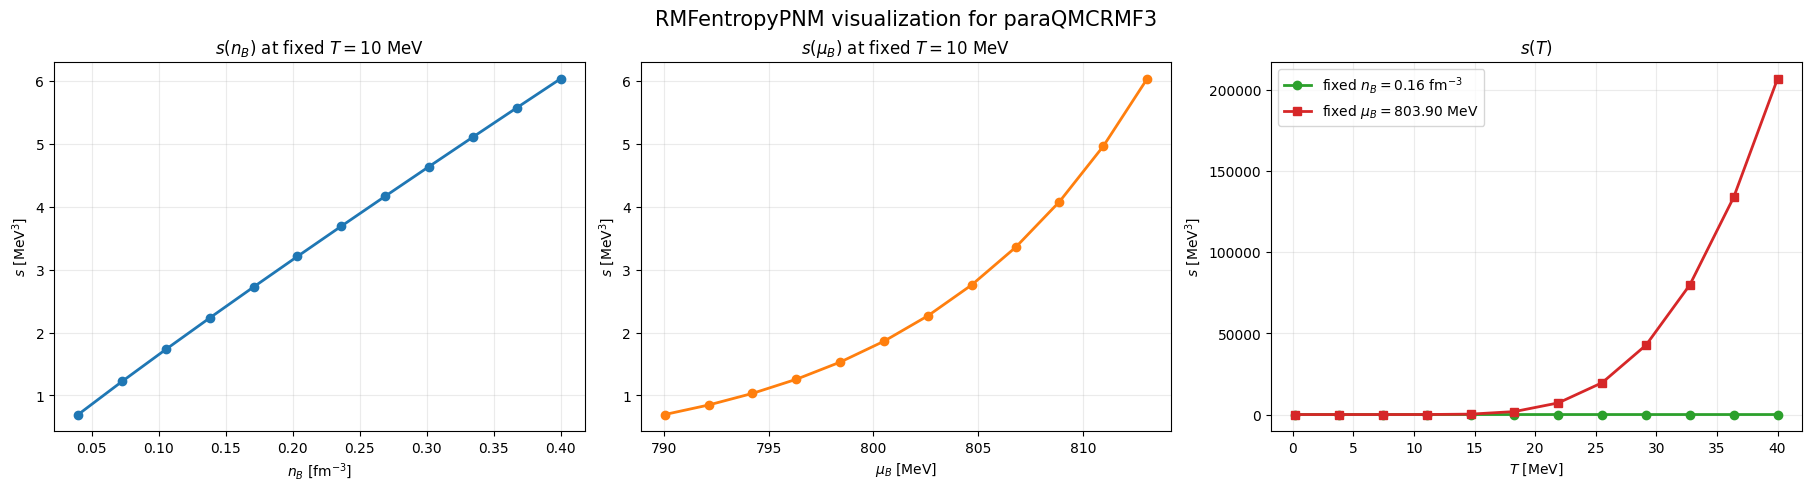

In [5]:
# VISUALIZE_RMFENTROPYPNM
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import IntegrationWarning

import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFentropyPNM, RMFsolvePNM

param_entropy_viz = para.paraQMCRMF3

# Fixed reference state for the nB and muB scans.
T_fixed_entropy_viz = 10.0
nB_ref_entropy_viz = 0.16

# Scan ranges. Keep these modest so the cell stays responsive.
nB_plot_vals = np.linspace(0.04, 0.40, 12)
T_plot_vals = np.linspace(0.2, 40.0, 12)


def entropy_from_nB(nB, T, param):
    entropy_val = RMFentropyPNM(nB, 'nB', T, param)
    return np.nan if entropy_val is None else float(np.asarray(entropy_val).item())


def entropy_from_muB(muB, T, param):
    entropy_val = RMFentropyPNM(muB, 'muB', T, param)
    return np.nan if entropy_val is None else float(np.asarray(entropy_val).item())


with warnings.catch_warnings():
    warnings.simplefilter('ignore', IntegrationWarning)
    muB_ref_entropy_viz = float(RMFsolvePNM(nB_ref_entropy_viz, T_fixed_entropy_viz, param_entropy_viz)[0][3])
    muB_min_entropy_viz = float(RMFsolvePNM(nB_plot_vals[0], T_fixed_entropy_viz, param_entropy_viz)[0][3])
    muB_max_entropy_viz = float(RMFsolvePNM(nB_plot_vals[-1], T_fixed_entropy_viz, param_entropy_viz)[0][3])
    muB_plot_vals = np.linspace(min(muB_min_entropy_viz, muB_max_entropy_viz), max(muB_min_entropy_viz, muB_max_entropy_viz), 12)

    s_vs_nB = np.array([entropy_from_nB(nB, T_fixed_entropy_viz, param_entropy_viz) for nB in nB_plot_vals])
    s_vs_muB = np.array([entropy_from_muB(muB, T_fixed_entropy_viz, param_entropy_viz) for muB in muB_plot_vals])
    s_vs_T_fixed_nB = np.array([entropy_from_nB(nB_ref_entropy_viz, T, param_entropy_viz) for T in T_plot_vals])
    s_vs_T_fixed_muB = np.array([entropy_from_muB(muB_ref_entropy_viz, T, param_entropy_viz) for T in T_plot_vals])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)

axes[0].plot(nB_plot_vals, s_vs_nB, marker='o', lw=2.0, color='C0')
axes[0].set_xlabel(r'$n_B$ [fm$^{-3}$]')
axes[0].set_ylabel(r'$s$ [MeV$^3$]')
axes[0].set_title(rf'$s(n_B)$ at fixed $T={T_fixed_entropy_viz:g}$ MeV')

axes[1].plot(muB_plot_vals, s_vs_muB, marker='o', lw=2.0, color='C1')
axes[1].set_xlabel(r'$\mu_B$ [MeV]')
axes[1].set_ylabel(r'$s$ [MeV$^3$]')
axes[1].set_title(rf'$s(\mu_B)$ at fixed $T={T_fixed_entropy_viz:g}$ MeV')

axes[2].plot(T_plot_vals, s_vs_T_fixed_nB, marker='o', lw=2.0, color='C2', label=rf'fixed $n_B={nB_ref_entropy_viz:.2f}$ fm$^{{-3}}$')
axes[2].plot(T_plot_vals, s_vs_T_fixed_muB, marker='s', lw=2.0, color='C3', label=rf'fixed $\mu_B={muB_ref_entropy_viz:.2f}$ MeV')
axes[2].set_xlabel(r'$T$ [MeV]')
axes[2].set_ylabel(r'$s$ [MeV$^3$]')
axes[2].set_title(r'$s(T)$')
axes[2].legend(fontsize=10)

for ax in axes:
    ax.grid(alpha=0.25)

fig.suptitle('RMFentropyPNM visualization for paraQMCRMF3', fontsize=15)
print(f'Reference state for T scans: nB = {nB_ref_entropy_viz:.3f} fm^-3, muB = {muB_ref_entropy_viz:.6f} MeV at T = {T_fixed_entropy_viz:.1f} MeV')
plt.show()


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fixed reference state: nB = 0.160 fm^-3, muB(T=10.0 MeV) = 803.901233 MeV
nB(T) at fixed muB ranges from 0.000000 to 34940.156085 fm^-3
muB(T) at fixed nB ranges from 313.093818 to 939.001489 MeV


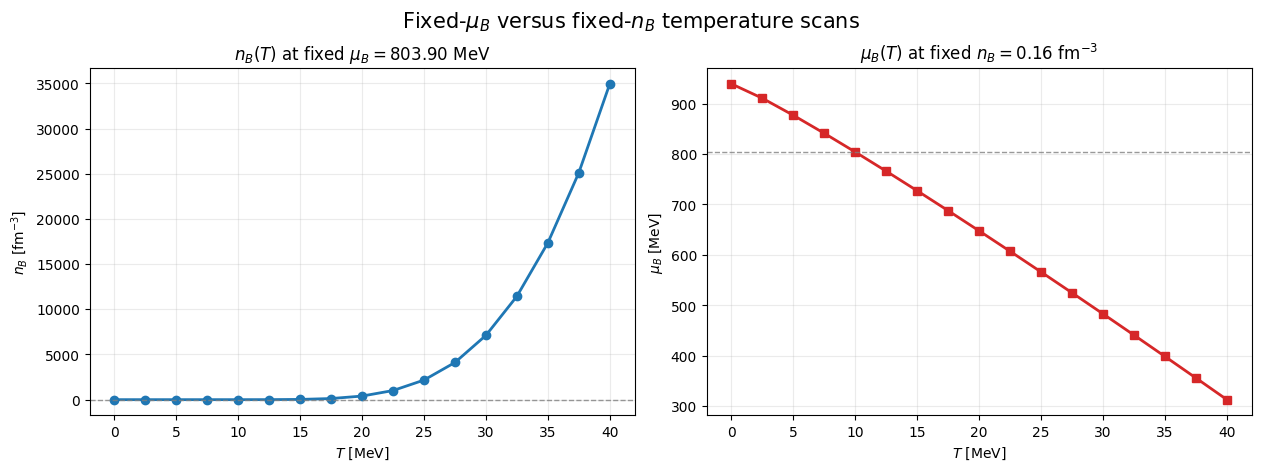

In [1]:
# PLOT_NB_OF_T_AT_FIXED_MUB_AND_MUB_OF_T_AT_FIXED_NB
import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolvePNM
from RMFsolver.phase_velocity import nB_NM

param_scan_compare = para.paraQMCRMF3
nB_fixed_scan_compare = 0.16
T_ref_scan_compare = 10.0
T_scan_compare_vals = np.linspace(0.0, 40.0, 17)

muB_fixed_scan_compare = float(RMFsolvePNM(nB_fixed_scan_compare, T_ref_scan_compare, param_scan_compare)[0][3])

nB_of_T_at_fixed_muB = np.array([
    nB_NM(muB_fixed_scan_compare, T, param=param_scan_compare)
    for T in T_scan_compare_vals
], dtype=float)

muB_of_T_at_fixed_nB = np.array([
    float(RMFsolvePNM(nB_fixed_scan_compare, T, param_scan_compare)[0][3])
    for T in T_scan_compare_vals
], dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), constrained_layout=True)

axes[0].plot(T_scan_compare_vals, nB_of_T_at_fixed_muB, marker='o', lw=2.0, color='C0')
axes[0].axhline(nB_fixed_scan_compare, color='0.5', lw=1.0, ls='--', alpha=0.8)
axes[0].set_xlabel(r'$T$ [MeV]')
axes[0].set_ylabel(r'$n_B$ [fm$^{-3}$]')
axes[0].set_title(rf'$n_B(T)$ at fixed $\mu_B={muB_fixed_scan_compare:.2f}$ MeV')

axes[1].plot(T_scan_compare_vals, muB_of_T_at_fixed_nB, marker='s', lw=2.0, color='C3')
axes[1].axhline(muB_fixed_scan_compare, color='0.5', lw=1.0, ls='--', alpha=0.8)
axes[1].set_xlabel(r'$T$ [MeV]')
axes[1].set_ylabel(r'$\mu_B$ [MeV]')
axes[1].set_title(rf'$\mu_B(T)$ at fixed $n_B={nB_fixed_scan_compare:.2f}$ fm$^{{-3}}$')

for ax in axes:
    ax.grid(alpha=0.25)

print(
    f'Fixed reference state: nB = {nB_fixed_scan_compare:.3f} fm^-3, '
    f'muB(T={T_ref_scan_compare:.1f} MeV) = {muB_fixed_scan_compare:.6f} MeV'
)
print(
    f'nB(T) at fixed muB ranges from {np.nanmin(nB_of_T_at_fixed_muB):.6f} '
    f'to {np.nanmax(nB_of_T_at_fixed_muB):.6f} fm^-3'
)
print(
    f'muB(T) at fixed nB ranges from {np.nanmin(muB_of_T_at_fixed_nB):.6f} '
    f'to {np.nanmax(muB_of_T_at_fixed_nB):.6f} MeV'
)

fig.suptitle(r'Fixed-$\mu_B$ versus fixed-$n_B$ temperature scans', fontsize=15)
plt.show()


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Reference comparison state: nB = 0.160 fm^-3, muB = 803.901233 MeV at T = 10.0 MeV
max |s_thermal - s_numerical| over nB scan       = 0.00902245
max |s_thermal - s_numerical| over muB scan      = 0.00902245
max |s_thermal - s_numerical| over T scan @ nB   = 1.51275
max |s_thermal - s_numerical| over T scan @ muB  = 0.018559


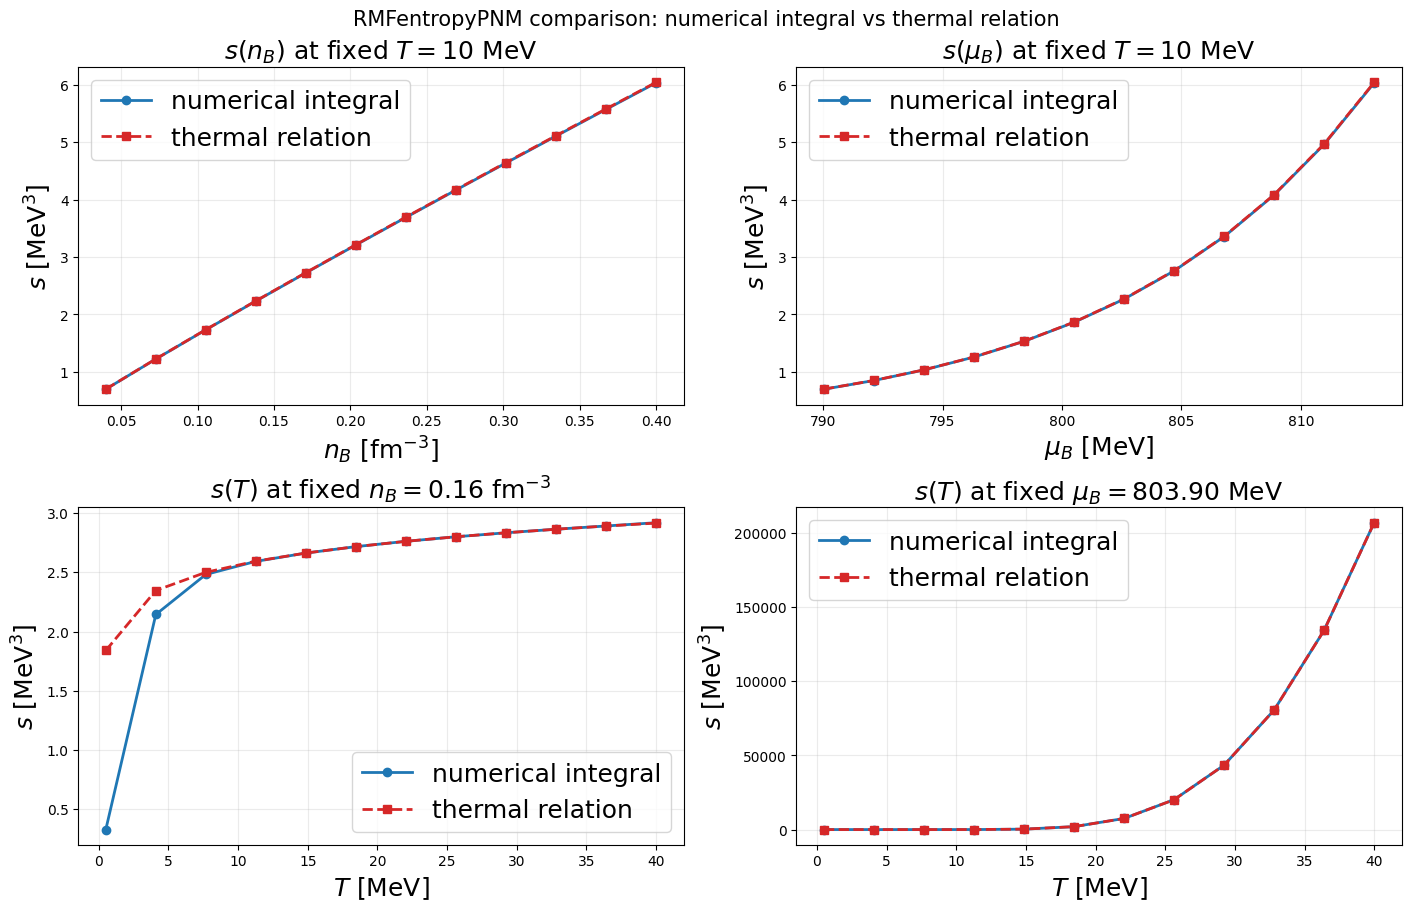

In [2]:
# COMPARE_RMFENTROPYPNM_TWO_METHODS
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import IntegrationWarning

import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFentropyPNM, RMFsolvePNM

param_entropy_compare = para.paraQMCRMF3
T_fixed_entropy_compare = 10.0
nB_ref_entropy_compare = 0.16

nB_compare_vals = np.linspace(0.04, 0.40, 12)
T_compare_vals = np.linspace(0.5, 40.0, 12)


def entropy_from_nB_method(nB, T, use_thermal):
    entropy_val = RMFentropyPNM(
        nB,
        'nB',
        T,
        param_entropy_compare,
        use_thermal=use_thermal,
    )
    return np.nan if entropy_val is None else float(np.asarray(entropy_val).item())


def entropy_from_muB_method(muB, T, use_thermal):
    entropy_val = RMFentropyPNM(
        muB,
        'muB',
        T,
        param_entropy_compare,
        use_thermal=use_thermal,
    )
    return np.nan if entropy_val is None else float(np.asarray(entropy_val).item())


with warnings.catch_warnings():
    warnings.simplefilter('ignore', IntegrationWarning)

    muB_ref_entropy_compare = float(RMFsolvePNM(nB_ref_entropy_compare, T_fixed_entropy_compare, param_entropy_compare)[0][3])
    muB_min_entropy_compare = float(RMFsolvePNM(nB_compare_vals[0], T_fixed_entropy_compare, param_entropy_compare)[0][3])
    muB_max_entropy_compare = float(RMFsolvePNM(nB_compare_vals[-1], T_fixed_entropy_compare, param_entropy_compare)[0][3])
    muB_compare_vals = np.linspace(min(muB_min_entropy_compare, muB_max_entropy_compare), max(muB_min_entropy_compare, muB_max_entropy_compare), 12)

    s_num_vs_nB = np.array([entropy_from_nB_method(nB, T_fixed_entropy_compare, use_thermal=False) for nB in nB_compare_vals])
    s_th_vs_nB = np.array([entropy_from_nB_method(nB, T_fixed_entropy_compare, use_thermal=True) for nB in nB_compare_vals])

    s_num_vs_muB = np.array([entropy_from_muB_method(muB, T_fixed_entropy_compare, use_thermal=False) for muB in muB_compare_vals])
    s_th_vs_muB = np.array([entropy_from_muB_method(muB, T_fixed_entropy_compare, use_thermal=True) for muB in muB_compare_vals])

    s_num_vs_T_fixed_nB = np.array([entropy_from_nB_method(nB_ref_entropy_compare, T, use_thermal=False) for T in T_compare_vals])
    s_th_vs_T_fixed_nB = np.array([entropy_from_nB_method(nB_ref_entropy_compare, T, use_thermal=True) for T in T_compare_vals])

    s_num_vs_T_fixed_muB = np.array([entropy_from_muB_method(muB_ref_entropy_compare, T, use_thermal=False) for T in T_compare_vals])
    s_th_vs_T_fixed_muB = np.array([entropy_from_muB_method(muB_ref_entropy_compare, T, use_thermal=True) for T in T_compare_vals])

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)

axes[0, 0].plot(nB_compare_vals, s_num_vs_nB, marker='o', lw=2.0, color='C0', label='numerical integral')
axes[0, 0].plot(nB_compare_vals, s_th_vs_nB, marker='s', lw=2.0, ls='--', color='C3', label='thermal relation')
axes[0, 0].set_xlabel(r'$n_B$ [fm$^{-3}$]', fontsize=18)
axes[0, 0].set_ylabel(r'$s$ [MeV$^3$]', fontsize=18)
axes[0, 0].set_title(rf'$s(n_B)$ at fixed $T={T_fixed_entropy_compare:g}$ MeV', fontsize=18)
axes[0, 0].legend(fontsize=18)

axes[0, 1].plot(muB_compare_vals, s_num_vs_muB, marker='o', lw=2.0, color='C0', label='numerical integral')
axes[0, 1].plot(muB_compare_vals, s_th_vs_muB, marker='s', lw=2.0, ls='--', color='C3', label='thermal relation')
axes[0, 1].set_xlabel(r'$\mu_B$ [MeV]', fontsize=18)
axes[0, 1].set_ylabel(r'$s$ [MeV$^3$]', fontsize=18)
axes[0, 1].set_title(rf'$s(\mu_B)$ at fixed $T={T_fixed_entropy_compare:g}$ MeV', fontsize=18)
axes[0, 1].legend(fontsize=18)

axes[1, 0].plot(T_compare_vals, s_num_vs_T_fixed_nB, marker='o', lw=2.0, color='C0', label='numerical integral')
axes[1, 0].plot(T_compare_vals, s_th_vs_T_fixed_nB, marker='s', lw=2.0, ls='--', color='C3', label='thermal relation')
axes[1, 0].set_xlabel(r'$T$ [MeV]', fontsize=18)
axes[1, 0].set_ylabel(r'$s$ [MeV$^3$]', fontsize=18)
axes[1, 0].set_title(rf'$s(T)$ at fixed $n_B={nB_ref_entropy_compare:.2f}$ fm$^{{-3}}$', fontsize=18)
axes[1, 0].legend(fontsize=18)

axes[1, 1].plot(T_compare_vals, s_num_vs_T_fixed_muB, marker='o', lw=2.0, color='C0', label='numerical integral')
axes[1, 1].plot(T_compare_vals, s_th_vs_T_fixed_muB, marker='s', lw=2.0, ls='--', color='C3', label='thermal relation')
axes[1, 1].set_xlabel(r'$T$ [MeV]', fontsize=18)
axes[1, 1].set_ylabel(r'$s$ [MeV$^3$]', fontsize=18)
axes[1, 1].set_title(rf'$s(T)$ at fixed $\mu_B={muB_ref_entropy_compare:.2f}$ MeV', fontsize=18)
axes[1, 1].legend(fontsize=18)

for ax in axes.flat:
    ax.grid(alpha=0.25)

print(f'Reference comparison state: nB = {nB_ref_entropy_compare:.3f} fm^-3, muB = {muB_ref_entropy_compare:.6f} MeV at T = {T_fixed_entropy_compare:.1f} MeV')
print(f'max |s_thermal - s_numerical| over nB scan       = {np.nanmax(np.abs(s_th_vs_nB - s_num_vs_nB)):.6g}')
print(f'max |s_thermal - s_numerical| over muB scan      = {np.nanmax(np.abs(s_th_vs_muB - s_num_vs_muB)):.6g}')
print(f'max |s_thermal - s_numerical| over T scan @ nB   = {np.nanmax(np.abs(s_th_vs_T_fixed_nB - s_num_vs_T_fixed_nB)):.6g}')
print(f'max |s_thermal - s_numerical| over T scan @ muB  = {np.nanmax(np.abs(s_th_vs_T_fixed_muB - s_num_vs_T_fixed_muB)):.6g}')

fig.suptitle('RMFentropyPNM comparison: numerical integral vs thermal relation', fontsize=15)
plt.show()


mean(s_num/s_th) over nB scan      = 0.99850682
mean(s_num/s_th) over muB scan     = 0.99850744
mean(s_num/s_th) over T scan @ nB  = 0.92372555
mean(s_num/s_th) over T scan @ muB = 0.99119631
min/max ratio over T scan @ nB     = 0.17774028, 1.00113983
min/max ratio over T scan @ muB    = 0.91092146, 1.00000002


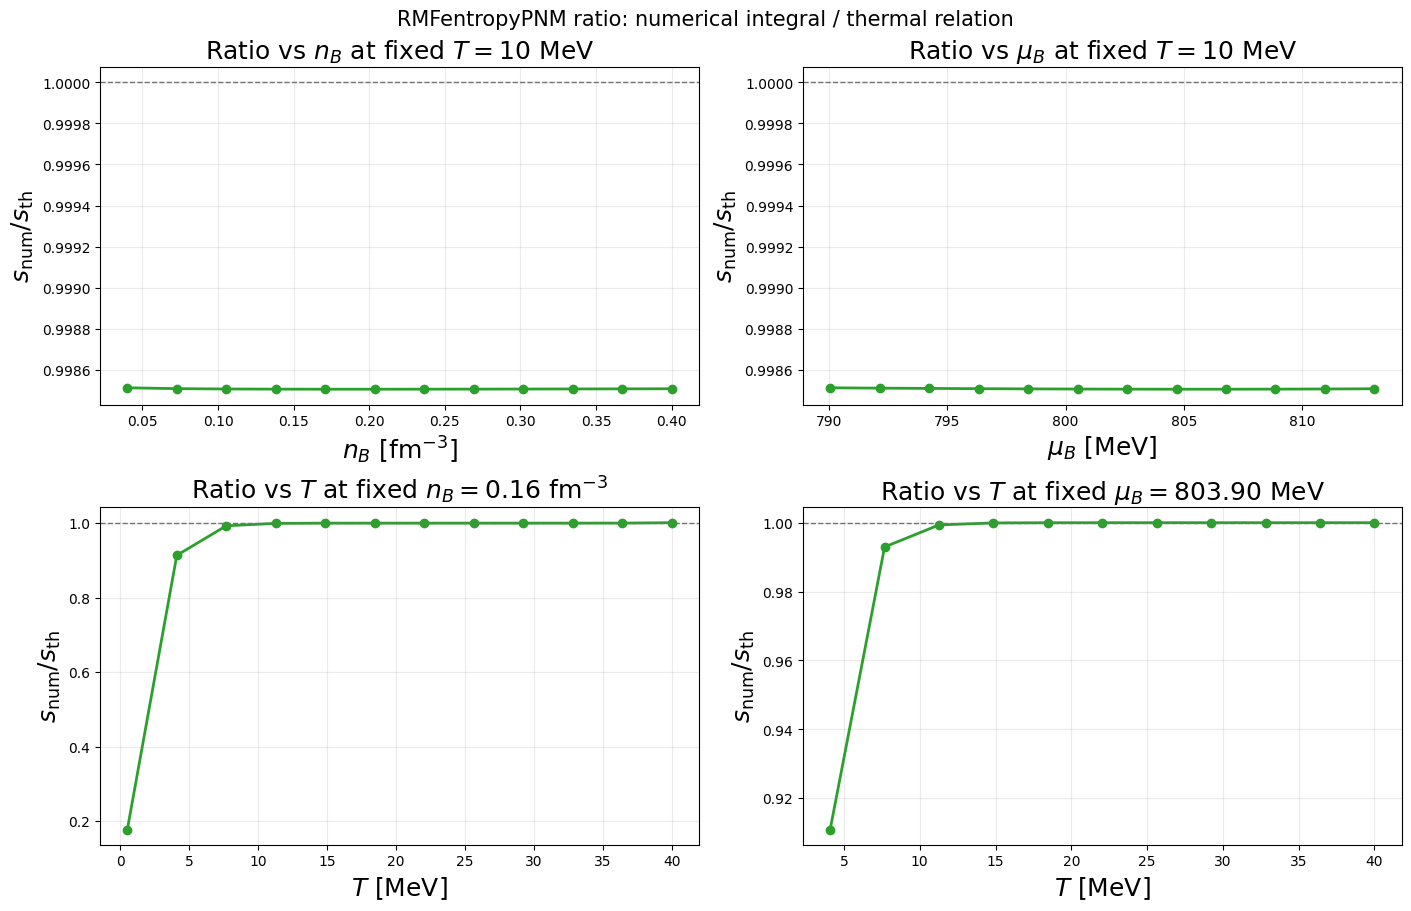

In [3]:
# RATIO_RMFENTROPYPNM_TWO_METHODS
import numpy as np
import matplotlib.pyplot as plt


def safe_ratio(numerator, denominator):
    numerator = np.asarray(numerator, dtype=float)
    denominator = np.asarray(denominator, dtype=float)
    return np.divide(
        numerator,
        denominator,
        out=np.full_like(numerator, np.nan, dtype=float),
        where=np.abs(denominator) > 1e-14,
    )


ratio_vs_nB = safe_ratio(s_num_vs_nB, s_th_vs_nB)
ratio_vs_muB = safe_ratio(s_num_vs_muB, s_th_vs_muB)
ratio_vs_T_fixed_nB = safe_ratio(s_num_vs_T_fixed_nB, s_th_vs_T_fixed_nB)
ratio_vs_T_fixed_muB = safe_ratio(s_num_vs_T_fixed_muB, s_th_vs_T_fixed_muB)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)

axes[0, 0].plot(nB_compare_vals, ratio_vs_nB, marker='o', lw=2.0, color='C2')
axes[0, 0].axhline(1.0, color='0.45', lw=1.0, ls='--')
axes[0, 0].set_xlabel(r'$n_B$ [fm$^{-3}$]', fontsize=18)
axes[0, 0].set_ylabel(r'$s_{\rm num}/s_{\rm th}$', fontsize=18)
axes[0, 0].set_title(rf'Ratio vs $n_B$ at fixed $T={T_fixed_entropy_compare:g}$ MeV', fontsize=18)

axes[0, 1].plot(muB_compare_vals, ratio_vs_muB, marker='o', lw=2.0, color='C2')
axes[0, 1].axhline(1.0, color='0.45', lw=1.0, ls='--')
axes[0, 1].set_xlabel(r'$\mu_B$ [MeV]', fontsize=18)
axes[0, 1].set_ylabel(r'$s_{\rm num}/s_{\rm th}$', fontsize=18)
axes[0, 1].set_title(rf'Ratio vs $\mu_B$ at fixed $T={T_fixed_entropy_compare:g}$ MeV', fontsize=18)

axes[1, 0].plot(T_compare_vals, ratio_vs_T_fixed_nB, marker='o', lw=2.0, color='C2')
axes[1, 0].axhline(1.0, color='0.45', lw=1.0, ls='--')
axes[1, 0].set_xlabel(r'$T$ [MeV]', fontsize=18)
axes[1, 0].set_ylabel(r'$s_{\rm num}/s_{\rm th}$', fontsize=18)
axes[1, 0].set_title(rf'Ratio vs $T$ at fixed $n_B={nB_ref_entropy_compare:.2f}$ fm$^{{-3}}$', fontsize=18)

axes[1, 1].plot(T_compare_vals, ratio_vs_T_fixed_muB, marker='o', lw=2.0, color='C2')
axes[1, 1].axhline(1.0, color='0.45', lw=1.0, ls='--')
axes[1, 1].set_xlabel(r'$T$ [MeV]', fontsize=18)
axes[1, 1].set_ylabel(r'$s_{\rm num}/s_{\rm th}$', fontsize=18)
axes[1, 1].set_title(rf'Ratio vs $T$ at fixed $\mu_B={muB_ref_entropy_compare:.2f}$ MeV', fontsize=18)

for ax in axes.flat:
    ax.grid(alpha=0.25)

print(f'mean(s_num/s_th) over nB scan      = {np.nanmean(ratio_vs_nB):.8f}')
print(f'mean(s_num/s_th) over muB scan     = {np.nanmean(ratio_vs_muB):.8f}')
print(f'mean(s_num/s_th) over T scan @ nB  = {np.nanmean(ratio_vs_T_fixed_nB):.8f}')
print(f'mean(s_num/s_th) over T scan @ muB = {np.nanmean(ratio_vs_T_fixed_muB):.8f}')
print(f'min/max ratio over T scan @ nB     = {np.nanmin(ratio_vs_T_fixed_nB):.8f}, {np.nanmax(ratio_vs_T_fixed_nB):.8f}')
print(f'min/max ratio over T scan @ muB    = {np.nanmin(ratio_vs_T_fixed_muB):.8f}, {np.nanmax(ratio_vs_T_fixed_muB):.8f}')

fig.suptitle(r'RMFentropyPNM ratio: numerical integral / thermal relation', fontsize=15)
plt.show()


In [15]:
from RMFsolver.Solver import RMFentropyPNM
import RMFsolver.constants as const
n0 = 0.16 * const.MeV_fm**3
RMFentropyPNM(2*n0, "nB", 0.058, para = para.paraQMCRMF3, use_thermal = True) #/RMFentropyPNM(2*n0, "nB", 10.0, para = para.paraQMCRMF3, use_thermal = False)

np.float64(767.4904280695422)

/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Reference quark state: nB = 0.320 fm^-3, muB = 865.133187 MeV at T = 10.0 MeV, muK = 0.0 MeV
Reference entropy: thermal = 2508668.88332, numerical = 2508668.88332, diff = 6.519e-09
max |s_thermal - s_numerical| over nB scan      = 7.72998e-08
max |s_thermal - s_numerical| over muB scan     = 7.54371e-08
max |s_thermal - s_numerical| over T scan @ nB  = 9.45161e-07
max |s_thermal - s_numerical| over T scan @ muB = 5.65953e-07


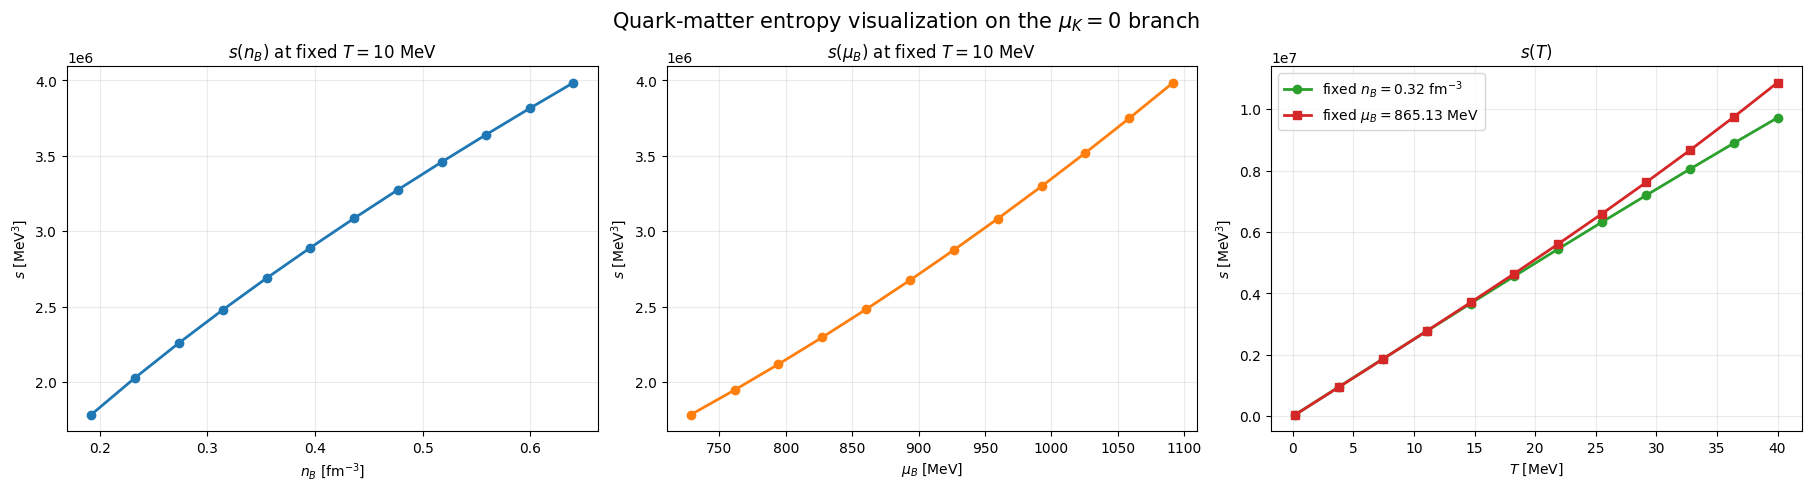

In [1]:
# TEST_AND_VISUALIZE_ENTROPYQM
import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.phase_velocity import entropyQM, _solve_muB_inf_at_muK0_from_nB

# Match the mu_K = 0 quark-matter branch used elsewhere in phase_velocity.py.
B14_entropy_qm = 180.0
ms_entropy_qm = 0.0
muK_entropy_qm = 0.0
T_fixed_entropy_qm = 10.0

n0_entropy_qm = 0.16 * const.MeV_fm**3
nB_ref_entropy_qm = 2.0 * n0_entropy_qm

# Scan ranges chosen to stay on the stable mu_K = 0 branch.
nB_plot_vals_entropy_qm = np.linspace(1.2, 4.0, 12) * n0_entropy_qm
T_plot_vals_entropy_qm = np.linspace(0.2, 40.0, 12)


def muB_from_nB_qm(nB, T):
    return float(
        _solve_muB_inf_at_muK0_from_nB(
            nB,
            B14_entropy_qm,
            T,
            ms=ms_entropy_qm,
        )
    )


def entropy_qm(muB, T, use_thermal=True):
    return float(
        entropyQM(
            muB,
            muK_entropy_qm,
            B14_entropy_qm,
            T,
            ms=ms_entropy_qm,
            include_em=False,
            use_thermal=use_thermal,
        )
    )


muB_ref_entropy_qm = muB_from_nB_qm(nB_ref_entropy_qm, T_fixed_entropy_qm)
muB_min_entropy_qm = muB_from_nB_qm(nB_plot_vals_entropy_qm[0], T_fixed_entropy_qm)
muB_max_entropy_qm = muB_from_nB_qm(nB_plot_vals_entropy_qm[-1], T_fixed_entropy_qm)
muB_plot_vals_entropy_qm = np.linspace(
    min(muB_min_entropy_qm, muB_max_entropy_qm),
    max(muB_min_entropy_qm, muB_max_entropy_qm),
    12,
)

s_ref_entropy_qm_th = entropy_qm(muB_ref_entropy_qm, T_fixed_entropy_qm, use_thermal=True)
s_ref_entropy_qm_num = entropy_qm(muB_ref_entropy_qm, T_fixed_entropy_qm, use_thermal=False)

assert np.isclose(s_ref_entropy_qm_th, s_ref_entropy_qm_num, rtol=1e-10, atol=1e-10)

s_th_vs_nB_qm = np.array([
    entropy_qm(muB_from_nB_qm(nB, T_fixed_entropy_qm), T_fixed_entropy_qm, use_thermal=True)
    for nB in nB_plot_vals_entropy_qm
])
s_num_vs_nB_qm = np.array([
    entropy_qm(muB_from_nB_qm(nB, T_fixed_entropy_qm), T_fixed_entropy_qm, use_thermal=False)
    for nB in nB_plot_vals_entropy_qm
])

s_th_vs_muB_qm = np.array([
    entropy_qm(muB, T_fixed_entropy_qm, use_thermal=True)
    for muB in muB_plot_vals_entropy_qm
])
s_num_vs_muB_qm = np.array([
    entropy_qm(muB, T_fixed_entropy_qm, use_thermal=False)
    for muB in muB_plot_vals_entropy_qm
])

muB_of_T_fixed_nB_qm = np.array([
    muB_from_nB_qm(nB_ref_entropy_qm, T)
    for T in T_plot_vals_entropy_qm
])
s_th_vs_T_fixed_nB_qm = np.array([
    entropy_qm(muB, T, use_thermal=True)
    for muB, T in zip(muB_of_T_fixed_nB_qm, T_plot_vals_entropy_qm)
])
s_num_vs_T_fixed_nB_qm = np.array([
    entropy_qm(muB, T, use_thermal=False)
    for muB, T in zip(muB_of_T_fixed_nB_qm, T_plot_vals_entropy_qm)
])

s_th_vs_T_fixed_muB_qm = np.array([
    entropy_qm(muB_ref_entropy_qm, T, use_thermal=True)
    for T in T_plot_vals_entropy_qm
])
s_num_vs_T_fixed_muB_qm = np.array([
    entropy_qm(muB_ref_entropy_qm, T, use_thermal=False)
    for T in T_plot_vals_entropy_qm
])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)

axes[0].plot(
    nB_plot_vals_entropy_qm / const.MeV_fm**3,
    s_th_vs_nB_qm,
    marker='o',
    lw=2.0,
    color='C0',
)
axes[0].set_xlabel(r'$n_B$ [fm$^{-3}$]')
axes[0].set_ylabel(r'$s$ [MeV$^3$]')
axes[0].set_title(rf'$s(n_B)$ at fixed $T={T_fixed_entropy_qm:g}$ MeV')

axes[1].plot(
    muB_plot_vals_entropy_qm,
    s_th_vs_muB_qm,
    marker='o',
    lw=2.0,
    color='C1',
)
axes[1].set_xlabel(r'$\mu_B$ [MeV]')
axes[1].set_ylabel(r'$s$ [MeV$^3$]')
axes[1].set_title(rf'$s(\mu_B)$ at fixed $T={T_fixed_entropy_qm:g}$ MeV')

axes[2].plot(
    T_plot_vals_entropy_qm,
    s_th_vs_T_fixed_nB_qm,
    marker='o',
    lw=2.0,
    color='C2',
    label=rf'fixed $n_B={nB_ref_entropy_qm / const.MeV_fm**3:.2f}$ fm$^{{-3}}$',
)
axes[2].plot(
    T_plot_vals_entropy_qm,
    s_th_vs_T_fixed_muB_qm,
    marker='s',
    lw=2.0,
    color='C3',
    label=rf'fixed $\mu_B={muB_ref_entropy_qm:.2f}$ MeV',
)
axes[2].set_xlabel(r'$T$ [MeV]')
axes[2].set_ylabel(r'$s$ [MeV$^3$]')
axes[2].set_title(r'$s(T)$')
axes[2].legend(fontsize=10)

for ax in axes:
    ax.grid(alpha=0.25)

print(
    f'Reference quark state: nB = {nB_ref_entropy_qm / const.MeV_fm**3:.3f} fm^-3, '
    f'muB = {muB_ref_entropy_qm:.6f} MeV at T = {T_fixed_entropy_qm:.1f} MeV, muK = {muK_entropy_qm:.1f} MeV'
)
print(
    f'Reference entropy: thermal = {s_ref_entropy_qm_th:.12g}, '
    f'numerical = {s_ref_entropy_qm_num:.12g}, '
    f'diff = {abs(s_ref_entropy_qm_th - s_ref_entropy_qm_num):.3e}'
)
print(f'max |s_thermal - s_numerical| over nB scan      = {np.nanmax(np.abs(s_th_vs_nB_qm - s_num_vs_nB_qm)):.6g}')
print(f'max |s_thermal - s_numerical| over muB scan     = {np.nanmax(np.abs(s_th_vs_muB_qm - s_num_vs_muB_qm)):.6g}')
print(f'max |s_thermal - s_numerical| over T scan @ nB  = {np.nanmax(np.abs(s_th_vs_T_fixed_nB_qm - s_num_vs_T_fixed_nB_qm)):.6g}')
print(f'max |s_thermal - s_numerical| over T scan @ muB = {np.nanmax(np.abs(s_th_vs_T_fixed_muB_qm - s_num_vs_T_fixed_muB_qm)):.6g}')

fig.suptitle(r'Quark-matter entropy visualization on the $\mu_K=0$ branch', fontsize=15)
plt.show()


mean(s_num/s_th) over nB scan      = 1.00000000
mean(s_num/s_th) over muB scan     = 1.00000000
mean(s_num/s_th) over T scan @ nB  = 1.00000000
mean(s_num/s_th) over T scan @ muB = 1.00000000
min/max ratio over T scan @ nB     = 1.00000000, 1.00000000
min/max ratio over T scan @ muB    = 1.00000000, 1.00000000


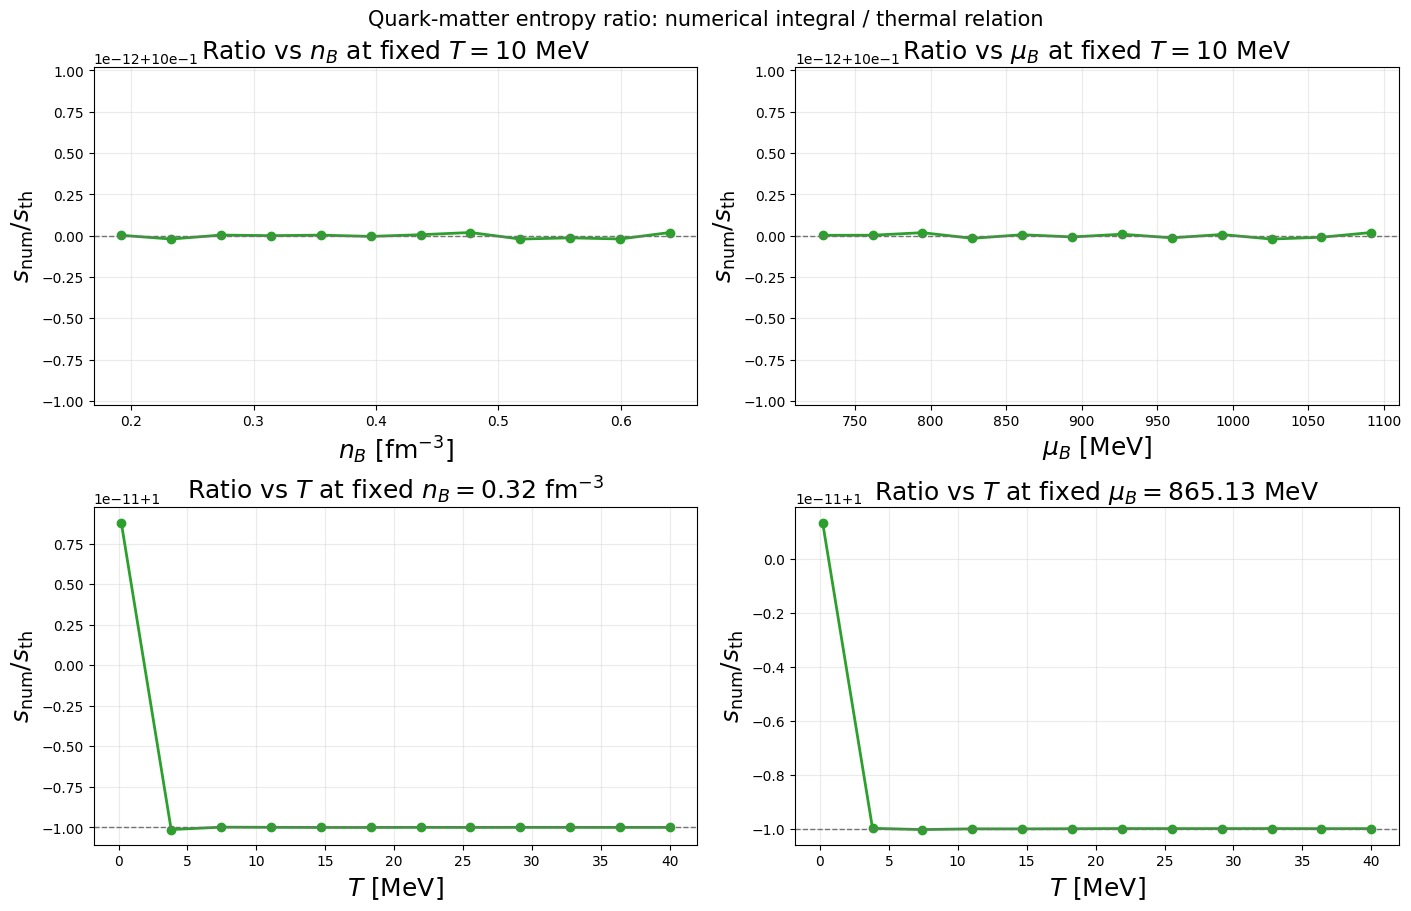

In [2]:
# RATIO_ENTROPYQM_TWO_METHODS
import numpy as np
import matplotlib.pyplot as plt

required_qm_entropy_names = [
    's_num_vs_nB_qm',
    's_th_vs_nB_qm',
    's_num_vs_muB_qm',
    's_th_vs_muB_qm',
    's_num_vs_T_fixed_nB_qm',
    's_th_vs_T_fixed_nB_qm',
    's_num_vs_T_fixed_muB_qm',
    's_th_vs_T_fixed_muB_qm',
    'nB_plot_vals_entropy_qm',
    'muB_plot_vals_entropy_qm',
    'T_plot_vals_entropy_qm',
    'T_fixed_entropy_qm',
    'nB_ref_entropy_qm',
    'muB_ref_entropy_qm',
    'const',
]

missing_qm_entropy_names = [name for name in required_qm_entropy_names if name not in globals()]
if missing_qm_entropy_names:
    raise RuntimeError(
        'Run the TEST_AND_VISUALIZE_ENTROPYQM cell first. Missing names: '
        + ', '.join(missing_qm_entropy_names)
    )


def safe_ratio_qm(numerator, denominator):
    numerator = np.asarray(numerator, dtype=float)
    denominator = np.asarray(denominator, dtype=float)
    return np.divide(
        numerator,
        denominator,
        out=np.full_like(numerator, np.nan, dtype=float),
        where=np.abs(denominator) > 1e-14,
    )


ratio_vs_nB_qm = safe_ratio_qm(s_num_vs_nB_qm, s_th_vs_nB_qm)
ratio_vs_muB_qm = safe_ratio_qm(s_num_vs_muB_qm, s_th_vs_muB_qm)
ratio_vs_T_fixed_nB_qm = safe_ratio_qm(s_num_vs_T_fixed_nB_qm, s_th_vs_T_fixed_nB_qm)
ratio_vs_T_fixed_muB_qm = safe_ratio_qm(s_num_vs_T_fixed_muB_qm, s_th_vs_T_fixed_muB_qm)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)

axes[0, 0].plot(nB_plot_vals_entropy_qm / const.MeV_fm**3, ratio_vs_nB_qm, marker='o', lw=2.0, color='C2')
axes[0, 0].axhline(1.0, color='0.45', lw=1.0, ls='--')
axes[0, 0].set_xlabel(r'$n_B$ [fm$^{-3}$]', fontsize=18)
axes[0, 0].set_ylabel(r'$s_{\rm num}/s_{\rm th}$', fontsize=18)
axes[0, 0].set_title(rf'Ratio vs $n_B$ at fixed $T={T_fixed_entropy_qm:g}$ MeV', fontsize=18)

axes[0, 1].plot(muB_plot_vals_entropy_qm, ratio_vs_muB_qm, marker='o', lw=2.0, color='C2')
axes[0, 1].axhline(1.0, color='0.45', lw=1.0, ls='--')
axes[0, 1].set_xlabel(r'$\mu_B$ [MeV]', fontsize=18)
axes[0, 1].set_ylabel(r'$s_{\rm num}/s_{\rm th}$', fontsize=18)
axes[0, 1].set_title(rf'Ratio vs $\mu_B$ at fixed $T={T_fixed_entropy_qm:g}$ MeV', fontsize=18)

axes[1, 0].plot(T_plot_vals_entropy_qm, ratio_vs_T_fixed_nB_qm, marker='o', lw=2.0, color='C2')
axes[1, 0].axhline(1.0, color='0.45', lw=1.0, ls='--')
axes[1, 0].set_xlabel(r'$T$ [MeV]', fontsize=18)
axes[1, 0].set_ylabel(r'$s_{\rm num}/s_{\rm th}$', fontsize=18)
axes[1, 0].set_title(rf'Ratio vs $T$ at fixed $n_B={nB_ref_entropy_qm / const.MeV_fm**3:.2f}$ fm$^{{-3}}$', fontsize=18)

axes[1, 1].plot(T_plot_vals_entropy_qm, ratio_vs_T_fixed_muB_qm, marker='o', lw=2.0, color='C2')
axes[1, 1].axhline(1.0, color='0.45', lw=1.0, ls='--')
axes[1, 1].set_xlabel(r'$T$ [MeV]', fontsize=18)
axes[1, 1].set_ylabel(r'$s_{\rm num}/s_{\rm th}$', fontsize=18)
axes[1, 1].set_title(rf'Ratio vs $T$ at fixed $\mu_B={muB_ref_entropy_qm:.2f}$ MeV', fontsize=18)

for ax in axes.flat:
    ax.grid(alpha=0.25)

print(f'mean(s_num/s_th) over nB scan      = {np.nanmean(ratio_vs_nB_qm):.8f}')
print(f'mean(s_num/s_th) over muB scan     = {np.nanmean(ratio_vs_muB_qm):.8f}')
print(f'mean(s_num/s_th) over T scan @ nB  = {np.nanmean(ratio_vs_T_fixed_nB_qm):.8f}')
print(f'mean(s_num/s_th) over T scan @ muB = {np.nanmean(ratio_vs_T_fixed_muB_qm):.8f}')
print(f'min/max ratio over T scan @ nB     = {np.nanmin(ratio_vs_T_fixed_nB_qm):.8f}, {np.nanmax(ratio_vs_T_fixed_nB_qm):.8f}')
print(f'min/max ratio over T scan @ muB    = {np.nanmin(ratio_vs_T_fixed_muB_qm):.8f}, {np.nanmax(ratio_vs_T_fixed_muB_qm):.8f}')

fig.suptitle(r'Quark-matter entropy ratio: numerical integral / thermal relation', fontsize=15)
plt.show()
